# Hexagon FBQC with a three-colour vertex Hadamard schedule

A three-colour hexagonal fusion network on a triangular lattice, with one
modification: the lattice **vertices** are themselves three-coloured, and each
vertex's cluster chain carries a Hadamard on one timestep in every three, at a
phase set by the vertex's colour -- each vertex Hadamarded at its **own**
colour's steps. Everything else -- the geometry, the standard destructive
fusion, and the six-step `rXX gZZ bXX rZZ gXX bZZ` schedule -- is the
unmodified hexagon code.

The notebook is self-contained: geometry, primitive, resource state, circuit,
checks and logicals are all built and verified here, against the circuit itself
(`has_flow`, `detector_error_model`).

| § | what happens |
|---|---|
| 1 | Geometry: the three-colour lattice, and the three-colour **vertex** classes |
| 2 | The fusion primitive: the standard destructive fusion, `XX` and `ZZ` |
| 3 | The resource state: cluster chains and the colour-phased Hadamard layer |
| 4 | The circuit: the six-step schedule |
| 5 | Checks: the six weight-12 hexagon checks, as an explicit table |
| 6 | Logicals: the six closed forms, as an explicit table |
| 7 | Preliminary thresholds: measurement error, and Z error on the chains |
| 8 | H-fusion on the XX-step crossing edges and the ZZ-step internal edges; checks and logicals re-derived |
| 9 | `p_meas` and `p_erase` thresholds, with and without the H-fusions |
| 10 | Biased measurement error: logical error rate vs the `XX`/`ZZ` outcome bias `δ` at fixed `p_meas` |
| 11 | Biased erasure: logical error rate vs `δ` at fixed `p_erase` |
| 12 | Measurement threshold vs `δ`, both circuits |
| 13 | Erasure threshold vs `δ`, plain circuit |
| 14 | Threshold vs `δ`: the unmodified hexagon code vs this one |

**What changes, and what does not.** The Hadamard layer lands on both endpoints
of every fusion it touches, so the *structure* of the code is untouched: the same
weight-12 hexagon checks on the same supports, the same six logicals, the same
ranks. What changes is **which of a fusion's two records each term pulls**.

§5 and §6 record that in two lookup tables, `CHECK_SPEC` and `LOGICAL_SPEC`,
which are the point of the notebook. Everything else builds the circuit they
address or verifies them against it.

In [1]:
import numpy as np
import stim
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from collections import Counter, defaultdict

print("stim", stim.__version__)

stim 1.16.0


---
## 1. Geometry

Points live on a triangular lattice indexed by integer axial coordinates
`(i, j)`. Every point has 6 nearest neighbours, offset by the six axial
directions `HEX_DIRS`. A **hexagon** centred at point `c` is the 6 points
`c + dir` for each of those directions, listed in a fixed cyclic order so that
consecutive entries are the hexagon's edges.

One **tile** groups three hexagons -- red, green, blue -- by centre offset from
a tile origin `(0, 0)`:

| colour | centre offset |
|---|---|
| red   | (0, -1) |
| green | (1, 0)  |
| blue  | (-1, 1) |

Tiles repeat on a square grid with translation vectors `(3, 0)` and `(0, 3)`.
Given `x_max, y_max` tiles, the lattice is periodic with period
`(3*x_max, 3*y_max)`.

Every edge of the tiling borders exactly two hexagons of two different colours;
the edge's own colour is the **third**, missing colour. Not every lattice site
is used: one third of the sites are neither a hexagon centre nor a vertex.

### The vertex three-colouring

This is the new ingredient. Each **vertex** is classed by its `x` coordinate
alone:

| `x % 3` | vertex class |
|---|---|
| 0 | red   |
| 1 | green |
| 2 | blue  |

Because the lattice period `3*x_max` is a multiple of 3, this is well defined
under the periodic wrap. It is not an arbitrary labelling: the sanity check
below shows it lines up exactly with the edge colouring -- an edge of colour `C`
either joins two vertices *both* of class `C`, or joins one vertex of each of the
two *other* classes. Equivalently, the class of a vertex is the colour of the
same-column edge at that vertex.

That dichotomy gets a name here, because §5's check rule turns on it:

- an **internal** edge has `dx = 0` -- both endpoints in the same column, both of
  the edge's own class;
- a **crossing** edge has `dx = +/-1` -- endpoints of the two classes other than
  the edge's colour.

In [2]:
# The six axial nearest-neighbour directions, in cyclic (hexagon-boundary) order.
HEX_DIRS = [(1, -1), (1, 0), (0, 1), (-1, 1), (-1, 0), (0, -1)]

# Hexagon centres within one tile, relative to the tile origin (0, 0).
TILE_OFFSETS = {"red": (0, -1), "green": (1, 0), "blue": (-1, 1)}

TILE_VECS = [(3, 0), (0, 3)]  # tile-to-tile translation

# Vertex class as a function of x % 3 -- the modification's new ingredient.
VERTEX_COLOURS = {0: "red", 1: "green", 2: "blue"}


class HexLattice:
    """Periodic tiling of the triangular lattice by red/green/blue hexagons.

    `x_max`, `y_max` tiles in each direction, wrapping periodically with
    period (3*x_max, 3*y_max). `vertex_colour` additionally classes every
    vertex red/green/blue by its x coordinate mod 3.
    """

    def __init__(self, x_max, y_max):
        self.x_max, self.y_max = x_max, y_max
        self.Lx, self.Ly = 3 * x_max, 3 * y_max

        # hexagons[(colour, centre)] = the 6 vertices, in cyclic order
        self.hexagons = {}
        for a in range(x_max):
            for b in range(y_max):
                tx, ty = 3 * a, 3 * b
                for colour, (dx, dy) in TILE_OFFSETS.items():
                    c = self.wrap((tx + dx, ty + dy))
                    verts = [self.wrap((c[0] + ox, c[1] + oy)) for ox, oy in HEX_DIRS]
                    self.hexagons[(colour, c)] = verts

        self.points = sorted(set(p for verts in self.hexagons.values() for p in verts))

        # every boundary edge -> the set of hexagon colours it borders
        edge_touch = defaultdict(set)
        for (colour, c), verts in self.hexagons.items():
            for k in range(6):
                p, q = verts[k], verts[(k + 1) % 6]
                edge_touch[frozenset((p, q))].add(colour)
        self.edge_touch = edge_touch

        # each edge borders exactly 2 colours; it is coloured by the 3rd
        all_colours = set(TILE_OFFSETS)
        self.edge_colour = {edge: (all_colours - cols).pop()
                            for edge, cols in edge_touch.items()}

    def wrap(self, p):
        return (p[0] % self.Lx, p[1] % self.Ly)

    def colour_of_edge(self, p, q):
        """Colour of the edge between two (adjacent) points, wrapped periodically."""
        return self.edge_colour[frozenset((self.wrap(p), self.wrap(q)))]

    def vertex_colour(self, p):
        """The vertex class of point p -- red/green/blue by x % 3."""
        return VERTEX_COLOURS[p[0] % 3]

    def is_internal(self, p, r):
        """True if the edge p-r lies within one column (dx = 0)."""
        return (r[0] - p[0]) % self.Lx == 0

    def edge_kind(self, p, r):
        return "internal" if self.is_internal(p, r) else "crossing"


net = HexLattice(4, 4)
print(f"tiles = {net.x_max * net.y_max}, hexagons = {len(net.hexagons)}, "
      f"points = {len(net.points)}, period = ({net.Lx}, {net.Ly})")

tiles = 16, hexagons = 48, points = 96, period = (12, 12)


### Sanity checks

The first three are the usual tiling checks: every edge borders exactly 2
hexagons of 2 different colours, the three colour pairs occur equally often, and
every point has exactly one red, one green and one blue edge (this last one is
what lets a single-colour fusion step consume every qubit exactly once).

The fourth is the one that matters for the modification: the vertex classes split
the points into exact thirds, and every edge is either internal (same class at
both ends, equal to its own colour) or crossing (the two other classes). Nothing
else occurs.

A corollary used throughout §3 and §5: **a vertex's edge of its own colour is
always its internal edge.** A crossing colour-`C` edge has no class-`C` endpoint
at all, so a class-`C` vertex's `C`-edge has nowhere else to go.

In [3]:
touch_dist = Counter(len(cols) for cols in net.edge_touch.values())
print("edge colour-touch-count distribution:", dict(touch_dist))
assert touch_dist.keys() == {2}, "every edge should border exactly 2 hexagon colours"

pair_dist = Counter(frozenset(cols) for cols in net.edge_touch.values())
print("colour-pair distribution:", {tuple(sorted(k)): v for k, v in pair_dist.items()})
assert len(set(pair_dist.values())) == 1, "colour pairs should occur equally often"

print("every hexagon has 6 distinct vertices:",
      all(len(set(v)) == 6 for v in net.hexagons.values()))

point_colour_degree = defaultdict(Counter)
for edge, colour in net.edge_colour.items():
    p, r = tuple(edge)
    point_colour_degree[p][colour] += 1
    point_colour_degree[r][colour] += 1
degree_profiles = Counter(tuple(sorted(point_colour_degree[p].items())) for p in net.points)
print("point colour-degree profiles:", dict(degree_profiles))
assert set(degree_profiles) == {(("blue", 1), ("green", 1), ("red", 1))}, \
    "every point should have exactly one red, one green, one blue edge"

# --- the vertex three-colouring, and how it meshes with the edge colouring
print("\nvertex class distribution:", dict(Counter(net.vertex_colour(p) for p in net.points)))
assert len(set(Counter(net.vertex_colour(p) for p in net.points).values())) == 1

profile = Counter()
for edge, ecol in net.edge_colour.items():
    p, r = tuple(edge)
    vcols = tuple(sorted((net.vertex_colour(p), net.vertex_colour(r))))
    profile[(ecol, net.edge_kind(p, r), vcols)] += 1

print("\n(edge colour, edge kind) -> vertex classes at its two ends:")
for (ecol, kind, vcols), n in sorted(profile.items()):
    print(f"   {ecol:>5} {kind:>8}: {vcols}   x{n}")

for (ecol, kind, vcols), n in profile.items():
    if kind == "internal":
        assert vcols == (ecol, ecol), "an internal edge joins two vertices of its own class"
    else:
        assert ecol not in vcols and vcols[0] != vcols[1], \
            "a crossing edge joins the two classes other than its own colour"
print("\nedge colouring and vertex colouring are compatible: OK")

# corollary: a vertex's own-colour edge is always internal
for p in net.points:
    for edge, ecol in net.edge_colour.items():
        if p in edge and ecol == net.vertex_colour(p):
            a, b = tuple(edge)
            assert net.is_internal(a, b), (p, edge)
print("a vertex's own-colour edge is always its internal edge: OK")

edge colour-touch-count distribution: {2: 144}
colour-pair distribution: {('blue', 'red'): 48, ('green', 'red'): 48, ('blue', 'green'): 48}
every hexagon has 6 distinct vertices: True
point colour-degree profiles: {(('blue', 1), ('green', 1), ('red', 1)): 96}

vertex class distribution: {'red': 32, 'green': 32, 'blue': 32}

(edge colour, edge kind) -> vertex classes at its two ends:
    blue crossing: ('green', 'red')   x32
    blue internal: ('blue', 'blue')   x16
   green crossing: ('blue', 'red')   x32
   green internal: ('green', 'green')   x16
     red crossing: ('blue', 'green')   x32
     red internal: ('red', 'red')   x16

edge colouring and vertex colouring are compatible: OK
a vertex's own-colour edge is always its internal edge: OK


### Visualise

Axial coordinates `(i, j)` map to the plane as `x = i + j/2`,
`y = j * sqrt(3)/2` -- under this map the six `HEX_DIRS` become unit vectors
spaced 60 degrees apart, so each hexagon renders as a regular hexagon. The
second plot places each point at its own raw `(i, j)` coordinate instead, with
vertices drawn in their **vertex class** colour and edges in their **edge**
colour, so both colourings are visible at once. Edges that wrap across the
periodic boundary are marked with a square at each endpoint rather than a line
drawn across the whole plot.

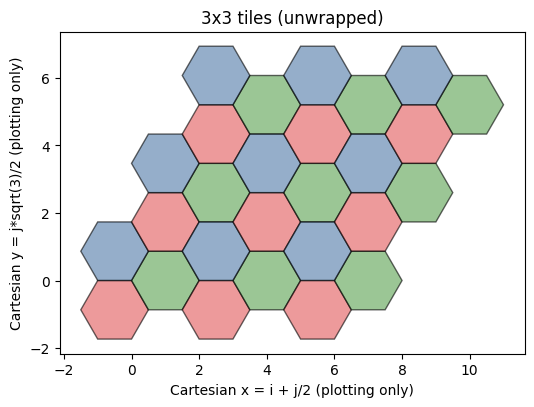

In [4]:
def to_xy(p):
    """Cartesian embedding for plotting only -- NOT the qubit (x, y) label.
    Qubits are always addressed by their axial (i, j) pair."""
    i, j = p
    return (i + 0.5 * j, (np.sqrt(3) / 2) * j)


COLOURS = {"red": "#e15759", "green": "#59a14f", "blue": "#4e79a7"}


def plot_patch(x_max, y_max, ax=None):
    """Plot an unwrapped x_max x y_max patch of tiles."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))
    for a in range(x_max):
        for b in range(y_max):
            tx, ty = 3 * a, 3 * b
            for colour, (dx, dy) in TILE_OFFSETS.items():
                c = (tx + dx, ty + dy)
                verts = [to_xy((c[0] + ox, c[1] + oy)) for ox, oy in HEX_DIRS]
                ax.add_patch(Polygon(verts, closed=True, facecolor=COLOURS[colour],
                                     edgecolor="black", linewidth=1, alpha=0.6))
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xlabel("Cartesian x = i + j/2 (plotting only)")
    ax.set_ylabel("Cartesian y = j*sqrt(3)/2 (plotting only)")
    ax.set_title(f"{x_max}x{y_max} tiles (unwrapped)")
    return ax


plot_patch(3, 3)
plt.show()

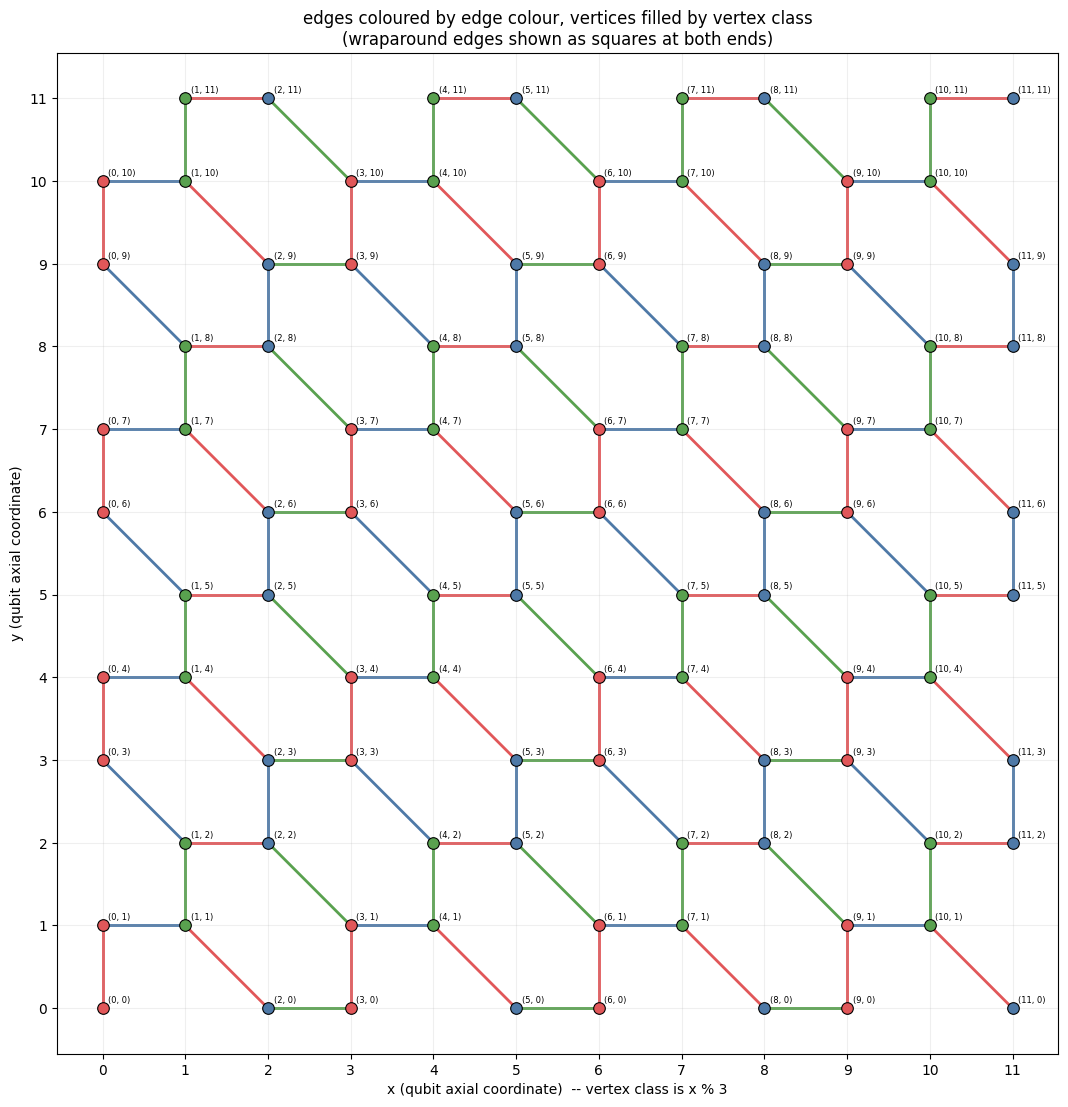

In [5]:
def plot_raw(net, ax=None, figsize=(13, 13)):
    """Raw axial plot: edges in their edge colour, vertices in their vertex class."""
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    for edge, colour in net.edge_colour.items():
        p, r = tuple(edge)
        di, dj = r[0] - p[0], r[1] - p[1]
        if (di, dj) in HEX_DIRS or (-di, -dj) in HEX_DIRS:
            ax.plot([p[0], r[0]], [p[1], r[1]], color=COLOURS[colour], linewidth=2, zorder=1)
        else:
            ax.plot(*p, marker="s", color=COLOURS[colour], markersize=5, zorder=1)
            ax.plot(*r, marker="s", color=COLOURS[colour], markersize=5, zorder=1)

    for p in net.points:
        ax.scatter(*p, color=COLOURS[net.vertex_colour(p)], s=70,
                   edgecolors="black", linewidths=0.8, zorder=2)
        ax.annotate(f"{p}", p, fontsize=6, xytext=(4, 4), textcoords="offset points", zorder=3)

    ax.set_xlabel("x (qubit axial coordinate)  -- vertex class is x % 3")
    ax.set_ylabel("y (qubit axial coordinate)")
    ax.set_xticks(range(net.Lx))
    ax.set_yticks(range(net.Ly))
    ax.grid(alpha=0.2)
    ax.set_aspect("equal")
    ax.set_title("edges coloured by edge colour, vertices filled by vertex class\n"
                 "(wraparound edges shown as squares at both ends)")
    return ax


plot_raw(net)
plt.show()

---
## 2. The fusion primitive

**Unmodified.** This network uses the ordinary destructive Bell fusion:

```
CNOT a b ; H a ; M a ; M b
```

It yields two records per fusion, in a fixed order:

| record | reads |
|---|---|
| `rec[-2]` | `X_a X_b`, the **`XX`** record |
| `rec[-1]` | `Z_a Z_b`, the **`ZZ`** record |

Both records exist at every fusion regardless of what that step's schedule calls
itself, so a check is free to pull either one. Throughout, `XX` and `ZZ` name the
record **slots** -- `rec[-2]` and `rec[-1]` -- not necessarily what they read
once the Hadamard layer of §3 is in place.

In [6]:
def fusion(circuit, a, b, p_meas=0.0):
    """The standard destructive fusion.

        CNOT a b ; H a ; M a ; M b

    Appends two records, in this order:

        rec[-2] = X_a X_b   ("XX")
        rec[-1] = Z_a Z_b   ("ZZ")

    `p_meas` flips each outcome independently with that probability."""
    circuit.append("CNOT", [a, b])
    circuit.append("H", [a])
    if p_meas > 0:
        circuit.append("M", [a, b], p_meas)
    else:
        circuit.append("M", [a, b])


def reads(pre_h=()):
    """{record -> the Pauli string it reads}, from stim's flow checker.
    `pre_h` lists qubits carrying an extra Hadamard just before the fusion."""
    c = stim.Circuit()
    for q in pre_h:
        c.append("H", [q])
    fusion(c, 0, 1)
    out = {}
    for ps in ("XX", "XZ", "ZX", "ZZ"):
        for rec in ("rec[-2]", "rec[-1]"):
            if c.has_flow(stim.Flow(f"{ps} -> {rec}")):
                out[rec] = ps
    return out


m = reads()
print(f"plain fusion:  rec[-2] = {m['rec[-2]']}   rec[-1] = {m['rec[-1]']}")
assert (m["rec[-2]"], m["rec[-1]"]) == ("XX", "ZZ")
print("slot XX is rec[-2], slot ZZ is rec[-1]: OK")

plain fusion:  rec[-2] = XX   rec[-1] = ZZ
slot XX is rec[-2], slot ZZ is rec[-1]: OK


---
## 3. The resource state: chains and the colour-phased Hadamard layer

Every lattice point gets `total_t = 6 * n_cycles` qubits, one per timestep,
addressed by `Spacetime.q(x, y, t)`. The state is prepared in three layers:

1. **`R` then `H`** -- every qubit in `|+>`.
2. **`CZ`** between the *same* vertex at adjacent timesteps. There are **no
   spatial CZs**: spatial connectivity comes entirely from the fusions. The
   resource state is a disjoint union of 1D cluster **chains**, one per lattice
   point, of length `total_t`, each **closed in time** -- the `t = total_t - 1`
   qubit is bonded back to `t = 0`.
3. **The Hadamard layer** -- the modification. An extra `H` on one qubit in
   every three along each chain, at a phase set by the chain's **vertex class**:

   | vertex class | Hadamard on timesteps |
   |---|---|
   | red   | `t % 3 == 0` |
   | green | `t % 3 == 1` |
   | blue  | `t % 3 == 2` |

### One rule instead of three

Vertex class is `x % 3` (§1), and in every row of that table the class residue
equals the time residue, so the whole layer collapses to

```
Hadamard on qubit (x, y, t)   <=>   (x - t) % 3 == 0
```

asserted equivalent to the per-class table below.

### Each vertex is Hadamarded at its own colour's steps

The schedule of §4 visits edge colours in the order red, green, blue, red, green,
blue, so the **step colour is also a function of `t % 3`**: `0` are the red steps,
`1` the green, `2` the blue. Lining that up against the table above, each vertex
class is Hadamarded exactly at the steps of **its own colour**.

A vertex's own-colour edge is always its *internal* edge (§1), and an internal
colour-`C` edge has **both** endpoints of class `C`. So at a colour-`C` step the
internal `C`-edges are fused between two Hadamarded vertices, while the crossing
`C`-edges join the two other classes and carry no Hadamard at all. The layer
therefore lands on both ends of a fusion or neither, and its whole effect is:

> **internal-edge fusions have their two record names exchanged** -- their slot
> `XX` reads `ZZ` and their slot `ZZ` reads `XX`. Crossing-edge fusions are
> untouched.

That single sentence is what the tables in §5 and §6 encode.

In [7]:
class Spacetime:
    """`net`'s points, each replicated over `total_t = 6 * n_cycles` timesteps
    that wrap periodically (timestep `total_t` is timestep `0`)."""

    def __init__(self, net, n_cycles):
        self.net = net
        self.n_cycles = n_cycles
        self.total_t = 6 * n_cycles
        self.point_id = {p: i for i, p in enumerate(net.points)}
        self.n_qubits = len(net.points) * self.total_t

    def q(self, x, y, t):
        return self.point_id[(x, y)] * self.total_t + (t % self.total_t)


# Hadamard phase per vertex class, as specified: each class at its own steps.
HAD_PHASE = {"red": 0, "green": 1, "blue": 2}
STEP_COLOUR_OF_RESIDUE = {0: "red", 1: "green", 2: "blue"}


def had_self(net, p, t):
    """The Hadamard layer: True iff qubit (p, t) carries the extra H."""
    return (p[0] - t) % 3 == 0


# the single diagonal rule must agree with the per-class table
for p in net.points:
    for t in range(12):
        assert had_self(net, p, t) == (t % 3 == HAD_PHASE[net.vertex_colour(p)])
print("(x - t) % 3 == 0  is equivalent to the per-class Hadamard table: OK")

print("\nvertex class -> the steps it is Hadamarded at:")
for cls in ("red", "green", "blue"):
    p = next(q for q in net.points if net.vertex_colour(q) == cls)
    ts = [t for t in range(6) if had_self(net, p, t)]
    sc = STEP_COLOUR_OF_RESIDUE[HAD_PHASE[cls]]
    print(f"   {cls:>5} vertex (e.g. {p}, x%3={p[0] % 3}): t%3=={HAD_PHASE[cls]} -> t in {ts}"
          f"  = the {sc} steps   {'SELF-ALIGNED' if sc == cls else 'other'}")

print("\nwhat a fusion's slots read:")
for pre, label in (((), "crossing edge (no Hadamard)"),
                   ((0, 1), "internal edge (both ends Hadamarded)")):
    m = reads(pre_h=pre)
    print(f"   {label:>38}:  slot XX reads {m['rec[-2]']},  slot ZZ reads {m['rec[-1]']}")
assert reads(pre_h=(0, 1)) == {"rec[-2]": "ZZ", "rec[-1]": "XX"}
print("\n=> internal-edge fusions have their two record names exchanged")

(x - t) % 3 == 0  is equivalent to the per-class Hadamard table: OK

vertex class -> the steps it is Hadamarded at:
     red vertex (e.g. (0, 0), x%3=0): t%3==0 -> t in [0, 3]  = the red steps   SELF-ALIGNED
   green vertex (e.g. (1, 1), x%3=1): t%3==1 -> t in [1, 4]  = the green steps   SELF-ALIGNED
    blue vertex (e.g. (2, 0), x%3=2): t%3==2 -> t in [2, 5]  = the blue steps   SELF-ALIGNED

what a fusion's slots read:
              crossing edge (no Hadamard):  slot XX reads XX,  slot ZZ reads ZZ
     internal edge (both ends Hadamarded):  slot XX reads ZZ,  slot ZZ reads XX

=> internal-edge fusions have their two record names exchanged


---
## 4. The circuit

**Unmodified.** The six-step schedule is exactly the one the hexagon code uses:
one edge colour per timestep, alternating the two record kinds.

| step | `t % 6` | edge colour | native kind | name |
|---|---|---|---|---|
| 1 | 0 | red   | `XX` | `rXX` |
| 2 | 1 | green | `ZZ` | `gZZ` |
| 3 | 2 | blue  | `XX` | `bXX` |
| 4 | 3 | red   | `ZZ` | `rZZ` |
| 5 | 4 | green | `XX` | `gXX` |
| 6 | 5 | blue  | `ZZ` | `bZZ` |

Every point has exactly one edge of each colour (§1), so a single-colour step is
a perfect matching of the lattice points and consumes every qubit at that
timestep exactly once. `t` wraps mod `total_t`, and that wrap is what closes each
chain.

The "native kind" is only the step's name; the tables of §5 and §6 say
independently which slot each term pulls.

In [8]:
# (edge colour, native record kind) for each of the 6 steps of one cycle
STEP_SCHEDULE = [("red", "XX"), ("green", "ZZ"), ("blue", "XX"),
                 ("red", "ZZ"), ("green", "XX"), ("blue", "ZZ")]
STEP_NAMES = [c[0] + k for c, k in STEP_SCHEDULE]   # rXX gZZ bXX rZZ gXX bZZ
OPPOSITE = {"XX": "ZZ", "ZZ": "XX"}


def build(st, p_meas=0.0, had=had_self, hfuse=None):
    """Prepare |+> everywhere, CZ each vertex to its own next (periodic)
    timestep, apply the Hadamard layer, then run the 6-step schedule.
    `hfuse(net, p, r, kind)`, if given, picks the fusions that become §8's
    H-fusion; by default every fusion is the plain one.

    Returns (circuit, records, nmeas) where
    records[(t, colour, kind, p, r)] = (XX record index, ZZ record index)."""
    net = st.net
    circuit = stim.Circuit()
    circuit.append("R", range(st.n_qubits))
    circuit.append("H", range(st.n_qubits))

    # layer 2: one closed 1D cluster chain per lattice point, along the time axis
    for p in net.points:
        for t in range(st.total_t):
            circuit.append("CZ", [st.q(*p, t), st.q(*p, t + 1)])

    # layer 3: the colour-phased Hadamard layer
    hq = sorted(st.q(*p, t) for p in net.points for t in range(st.total_t) if had(net, p, t))
    if hq:
        circuit.append("H", hq)

    colour_edges = defaultdict(list)
    for edge, colour in net.edge_colour.items():
        colour_edges[colour].append(tuple(edge))

    records, n = {}, 0
    for c in range(st.n_cycles):
        for step, (colour, kind) in enumerate(STEP_SCHEDULE):
            t = 6 * c + step
            for (p, r) in colour_edges[colour]:
                if hfuse is not None and hfuse(net, p, r, kind):
                    circuit.append("H", [st.q(*p, t), st.q(*r, t)])   # §8 H-fusion
                fusion(circuit, st.q(*p, t), st.q(*r, t), p_meas)
                records[(t, colour, kind, p, r)] = (n, n + 1)   # (XX slot, ZZ slot)
                n += 2

    return circuit, records, n


def find_record(records, t, colour, kind, p, r):
    """(XX record, ZZ record); does not care which way round the edge is given."""
    return records.get((t, colour, kind, p, r)) or records[(t, colour, kind, r, p)]


def slot(pair, kind):
    """Pick the XX or the ZZ record of one fusion."""
    return pair[0] if kind == "XX" else pair[1]


st = Spacetime(net, n_cycles=2)
circ, records, nmeas = build(st)
print(f"points = {len(net.points)}, total_t = {st.total_t}, qubits = {st.n_qubits}")
print(f"fusions = {nmeas // 2}, measurement records = {nmeas}")
print(f"Hadamard layer covers "
      f"{sum(1 for p in net.points for t in range(st.total_t) if had_self(net, p, t))}"
      f" of {st.n_qubits} qubits (expect one third)")

points = 96, total_t = 12, qubits = 1152
fusions = 576, measurement records = 1152
Hadamard layer covers 384 of 1152 qubits (expect one third)


### Sanity check: every qubit consumed exactly once

Each of `st.n_qubits` qubits must be consumed by exactly one fusion. If a qubit
is consumed twice the circuit is nonsense; if zero times it dangles.

In [9]:
used = Counter()
for (t, colour, kind, p, r) in records:
    used[st.q(*p, t)] += 1
    used[st.q(*r, t)] += 1
print("distribution of 'times consumed':", dict(Counter(used.values())))
bad = [i for i in range(st.n_qubits) if used[i] != 1]
print("qubits not consumed exactly once:", len(bad) if bad else "none")
assert not bad

per_t = Counter(t for (t, *_rest) in records)
print("fusions per timestep, distribution of counts:", dict(Counter(per_t.values())))
print("expected per timestep:", len(net.points) // 2)

# the record slots are positionally fixed at every step
for step, (colour, kind) in enumerate(STEP_SCHEDULE):
    (t, _c, _k, p, r) = next(k for k in records if k[0] == step and k[1] == colour)
    r_xx, r_zz = find_record(records, t, colour, kind, p, r)
    assert r_zz == r_xx + 1
print("XX is rec[-2] and ZZ is rec[-1] at every step: OK")

distribution of 'times consumed': {1: 1152}
qubits not consumed exactly once: none
fusions per timestep, distribution of counts: {48: 12}
expected per timestep: 48
XX is rec[-2] and ZZ is rec[-1] at every step: OK


---
## 5. Checks

A hexagon's six boundary edges are never its own colour (§1), so they split 3 and
3 between the other two colours, **one internal and two crossing** of each. A
check takes a 6-step window, drops the two steps of the hexagon's own colour, and
uses the remaining **4 steps x 3 same-coloured boundary edges = weight 12**. Each
hexagon carries two -- an `X` check and a `Z` check, the same window shifted by 3
steps -- so there are 6 check types and `2 x (number of hexagons)` per cycle.

### `CHECK_SPEC`

One row per term, four terms per check:

```
(dt, edge colour, slot on the internal edge, slot on the two crossing edges)
```

`dt` is the timestep relative to the start of the cycle, so `dt >= 6` reaches
into the next one; cycle `c` uses `(6*c + dt) % total_t`.

| check | term 1 | term 2 | term 3 | term 4 |
|---|---|---|---|---|
| **blue X**  | t=0 red `XX`/`ZZ`   | t=1 green `ZZ`/`XX` | t=3 red `ZZ`/`XX`   | t=4 green `XX`/`ZZ` |
| **blue Z**  | t=3 red `XX`/`ZZ`   | t=4 green `ZZ`/`XX` | t=6 red `ZZ`/`XX`   | t=7 green `XX`/`ZZ` |
| **red X**   | t=4 green `XX`/`ZZ` | t=5 blue `ZZ`/`XX`  | t=7 green `ZZ`/`XX` | t=8 blue `XX`/`ZZ` |
| **red Z**   | t=1 green `XX`/`ZZ` | t=2 blue `ZZ`/`XX`  | t=4 green `ZZ`/`XX` | t=5 blue `XX`/`ZZ` |
| **green X** | t=2 blue `XX`/`ZZ`  | t=3 red `ZZ`/`XX`   | t=5 blue `ZZ`/`XX`  | t=6 red `XX`/`ZZ` |
| **green Z** | t=5 blue `XX`/`ZZ`  | t=6 red `ZZ`/`XX`   | t=8 blue `ZZ`/`XX`  | t=9 red `XX`/`ZZ` |

(each cell reads *internal* `/` *crossing*)

Two regularities, asserted in the cell below rather than relied on:

- the crossing slots always run **`ZZ, XX, XX, ZZ`** across the four terms, and
  the internal slots are always their exact opposite, **`XX, ZZ, ZZ, XX`** --
  identical for all six check types;
- the internal and crossing slots differ in **every** term, so each check has 4
  internal terms disagreeing with its 8 crossing ones. That is the Hadamard
  layer's name-exchange of §3 showing up in the table.

In [10]:
# (dt, edge colour, slot on the INTERNAL edge, slot on the two CROSSING edges)
CHECK_SPEC = {
    ("blue",  "X"): [(0, "red",   "XX", "ZZ"), (1, "green", "ZZ", "XX"),
                     (3, "red",   "ZZ", "XX"), (4, "green", "XX", "ZZ")],
    ("blue",  "Z"): [(3, "red",   "XX", "ZZ"), (4, "green", "ZZ", "XX"),
                     (6, "red",   "ZZ", "XX"), (7, "green", "XX", "ZZ")],
    ("red",   "X"): [(4, "green", "XX", "ZZ"), (5, "blue",  "ZZ", "XX"),
                     (7, "green", "ZZ", "XX"), (8, "blue",  "XX", "ZZ")],
    ("red",   "Z"): [(1, "green", "XX", "ZZ"), (2, "blue",  "ZZ", "XX"),
                     (4, "green", "ZZ", "XX"), (5, "blue",  "XX", "ZZ")],
    ("green", "X"): [(2, "blue",  "XX", "ZZ"), (3, "red",   "ZZ", "XX"),
                     (5, "blue",  "ZZ", "XX"), (6, "red",   "XX", "ZZ")],
    ("green", "Z"): [(5, "blue",  "XX", "ZZ"), (6, "red",   "ZZ", "XX"),
                     (8, "blue",  "ZZ", "XX"), (9, "red",   "XX", "ZZ")],
}

# the table must agree with the schedule and with its own regularities
for (hex_colour, xz), terms in CHECK_SPEC.items():
    assert len(terms) == 4
    for (dt, edge_colour, k_int, k_cross) in terms:
        colour, _native = STEP_SCHEDULE[dt % 6]
        assert colour == edge_colour, \
            f"{hex_colour} {xz}: t={dt} is a {colour} step, table says {edge_colour}"
        assert edge_colour != hex_colour, "a hexagon never borders its own colour"
        assert k_int == OPPOSITE[k_cross], "internal and crossing always disagree"
    assert [k for (_d, _c, _i, k) in terms] == ["ZZ", "XX", "XX", "ZZ"]
    assert [k for (_d, _c, k, _x) in terms] == ["XX", "ZZ", "ZZ", "XX"]
print("CHECK_SPEC agrees with the step schedule: OK")
print("every check has crossing pattern ZZ, XX, XX, ZZ and internal XX, ZZ, ZZ, XX")

CHECK_SPEC agrees with the step schedule: OK
every check has crossing pattern ZZ, XX, XX, ZZ and internal XX, ZZ, ZZ, XX


### Building the checks

`hexagon_boundary_by_colour` groups a hexagon's six boundary edges by edge
colour; within each group the one internal edge and the two crossing ones are
distinguished by `net.is_internal`, which is all `CHECK_SPEC` needs to be read
off.

In [11]:
def hexagon_boundary_by_colour(net, colour, centre):
    """The 6 boundary edges of hexagon (colour, centre), grouped by edge colour
    (3 of each of the 2 non-native colours: 1 internal + 2 crossing)."""
    verts = net.hexagons[(colour, centre)]
    by_colour = defaultdict(list)
    for k in range(6):
        p, r = verts[k], verts[(k + 1) % 6]
        by_colour[net.colour_of_edge(p, r)].append((p, r))
    return by_colour


def check_rows(st, records, nmeas, spec=CHECK_SPEC):
    """One GF(2) row per (hexagon, X/Z, cycle), straight from the table."""
    net = st.net
    rows, meta = [], []
    for (hex_colour, centre) in net.hexagons:
        by_colour = hexagon_boundary_by_colour(net, hex_colour, centre)
        for xz in ("X", "Z"):
            for c in range(st.n_cycles):
                v = np.zeros(nmeas, dtype=np.uint8)
                for (dt, edge_colour, k_int, k_cross) in spec[(hex_colour, xz)]:
                    t = (6 * c + dt) % st.total_t
                    colour, native = STEP_SCHEDULE[t % 6]
                    for (p, r) in by_colour[colour]:
                        pair = find_record(records, t, colour, native, p, r)
                        v[slot(pair, k_int if net.is_internal(p, r) else k_cross)] ^= 1
                rows.append(v)
                meta.append((hex_colour, centre, xz, c))
    return np.array(rows, dtype=np.uint8), meta


# one hexagon's boundary, to show the 1-internal / 2-crossing split
centre = next(ct for (col, ct) in net.hexagons if col == "blue")
print(f"blue hexagon @ {centre}, boundary grouped by edge colour:")
for ecol, edges in sorted(hexagon_boundary_by_colour(net, "blue", centre).items()):
    for (p, r) in edges:
        print(f"   {ecol:>5} {net.edge_kind(p, r):>8}  {p}-{r}")

checks, check_meta = check_rows(st, records, nmeas)
print(f"\nhexagons = {len(net.hexagons)}, cycles = {st.n_cycles} -> {len(checks)} checks "
      f"(expect {len(net.hexagons) * 2 * st.n_cycles})")
print("weight distribution:", dict(Counter(checks.sum(axis=1).tolist())))

blue hexagon @ (11, 1), boundary grouped by edge colour:
   green crossing  (0, 1)-(11, 2)
   green internal  (10, 2)-(10, 1)
   green crossing  (11, 0)-(0, 0)
     red internal  (0, 0)-(0, 1)
     red crossing  (11, 2)-(10, 2)
     red crossing  (10, 1)-(11, 0)

hexagons = 48, cycles = 2 -> 192 checks (expect 192)
weight distribution: {12: 192}


### Verification

`detector_error_model()` refuses to build if any detector is not deterministic in
the noiseless circuit, so one call validates all of them at once. Then every
check is confirmed individually with `has_flow`, broken down by hexagon colour
and type.

In [12]:
def rref(A):
    """Row-reduced echelon form over GF(2); returns (rows, pivot columns)."""
    R = A.copy() % 2
    rows, cols = R.shape
    piv, r = [], 0
    for c in range(cols):
        idx = np.flatnonzero(R[r:, c])
        if idx.size == 0:
            continue
        p = r + idx[0]
        R[[r, p]] = R[[p, r]]
        m = R[:, c].astype(bool).copy(); m[r] = False
        R[m] ^= R[r]
        piv.append(c); r += 1
        if r == rows:
            break
    return R[:r], piv


def rank(M):
    M = np.asarray(M, dtype=np.uint8)
    return rref(M)[0].shape[0] if len(M) else 0


def add_detectors(circuit, rows, nmeas):
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for row in rows:
        circuit.append("DETECTOR", [tgt(i) for i in np.flatnonzero(row)])


probe = circ.copy()
add_detectors(probe, checks, nmeas)
try:
    probe.detector_error_model(decompose_errors=True)
    print(f"DEM built: all {probe.num_detectors} detectors deterministic")
except Exception as e:
    print("DEM FAILED:", str(e).split("\n")[0])

ok = Counter()
for row, (hc, _centre, xz, _c) in zip(checks, check_meta):
    f = stim.Flow("1 -> " + " xor ".join(f"rec[{int(j) - nmeas}]" for j in np.flatnonzero(row)))
    ok[(hc, xz, circ.has_flow(f))] += 1
print("\nper-check has_flow:")
for hc in ("red", "green", "blue"):
    line = "   "
    for xz in ("X", "Z"):
        good, bad = ok[(hc, xz, True)], ok[(hc, xz, False)]
        line += f"{hc:>5} {xz}: {good:3d} valid / {good + bad:3d}    "
    print(line)
assert all(not ok[(hc, xz, False)] for hc in ("red", "green", "blue") for xz in ("X", "Z"))
print(f"\nall {len(checks)} checks deterministic; rank = {rank(checks)}")

DEM built: all 192 detectors deterministic



per-check has_flow:
     red X:  32 valid /  32      red Z:  32 valid /  32    
   green X:  32 valid /  32    green Z:  32 valid /  32    
    blue X:  32 valid /  32     blue Z:  32 valid /  32    

all 192 checks deterministic; rank = 190


---
## 6. Logicals

Six logical operators, in three families of two. Like the checks they are given
as a table, `LOGICAL_SPEC`, naming the family and its parameters; the three
builders below read it.

Two of the six (Vertical Z, Horizontal Z) **march** a single column or row across
the whole lattice, one position every 2 timesteps, so they only close after
sweeping every column/row exactly once. That needs the full period
`n_cycles = x_max`, not the 2-cycle circuit of §4-5, so this section rebuilds its
own circuit at that size on the same lattice.

| logical | family | what it covers |
|---|---|---|
| Timelike X / Z | `timelike` | every edge of all three colours, at 3 consecutive timesteps of a fixed cycle |
| Vertical Z / Horizontal Z | `marching` | one column (row), swept across the lattice, 1 position per 2 timesteps |
| Vertical X / Horizontal X | `stationary` | two adjacent columns (rows), fixed, repeating every cycle |

**The internal/crossing split applies here too**, exactly as in `CHECK_SPEC`:
every kind named in `LOGICAL_SPEC` is the slot for a **crossing** edge, and
internal edges take the opposite. `slot_for` is the single place that is applied.

**One subtlety worth flagging.** The `marching` family's `own`/`ext` distinction
is about the *marching axis* -- for a row sweep, "own" means same `y`. That is
**not** the same notion as internal, which always means same `x`, because the
Hadamard layer keys off `x` alone. Both are used, and they are kept separate.

In [13]:
st6 = Spacetime(net, n_cycles=net.x_max)
circ6, records6, nmeas6 = build(st6)
print(f"st6: n_cycles={st6.n_cycles}, total_t={st6.total_t}, "
      f"n_qubits={st6.n_qubits}, nmeas={nmeas6}")


def slot_for(pair, kind, net, p, r):
    """Pick a record, applying the internal-edge name exchange of §3.
    `kind` is always the slot for a crossing edge."""
    return slot(pair, OPPOSITE[kind] if net.is_internal(p, r) else kind)

st6: n_cycles=4, total_t=24, n_qubits=2304, nmeas=2304


### Column/row native colour

Every point's edges split by *axis*: an edge joining two points with the same
`axis` coordinate, versus one joining `k` to `k+1`. Both are a function of
`k % 3` only, colour-wise. Rather than assume this, derive both tables directly
from `net.edge_colour` and assert each residue gives one consistent colour.

The `x` table reproduces the vertex classing of §1 -- the internal colour of
column `k` *is* the class of the vertices in it.

In [14]:
def internal_crossing_tables(net, axis):
    """Colour of the same-`axis`-coordinate edge and the k->k+1 edge, by k%3."""
    length = net.Lx if axis == 0 else net.Ly
    internal, crossing = defaultdict(set), defaultdict(set)
    for edge, colour in net.edge_colour.items():
        p, r = tuple(edge)
        d = (r[axis] - p[axis]) % length
        if d == 0:
            internal[p[axis] % 3].add(colour)
        elif d == 1:
            crossing[p[axis] % 3].add(colour)
        elif d == length - 1:
            crossing[r[axis] % 3].add(colour)
        else:
            raise ValueError("edge spans more than one lattice step", edge, d)
    assert all(len(v) == 1 for v in internal.values()), internal
    assert all(len(v) == 1 for v in crossing.values()), crossing
    return {k: v.pop() for k, v in internal.items()}, {k: v.pop() for k, v in crossing.items()}


_pce_cache = {}

def point_colour_edge(net, p, colour):
    """The unique edge of `colour` touching point p (every point has exactly one
    -- checked in §1). Indexed once per lattice; the marching loop would
    otherwise rescan every edge."""
    key = id(net)
    if key not in _pce_cache:
        table = {}
        for edge, c in net.edge_colour.items():
            a, b = tuple(edge)
            table[(a, c)] = (a, b)
            table[(b, c)] = (a, b)
        _pce_cache[key] = table
    return _pce_cache[key][(p, colour)]


NATIVE_OF_X, CROSSING_OF_X = internal_crossing_tables(net, axis=0)
NATIVE_OF_Y, CROSSING_OF_Y = internal_crossing_tables(net, axis=1)
print("x: same-x", NATIVE_OF_X, " k->k+1", CROSSING_OF_X)
print("y: same-y", NATIVE_OF_Y, " k->k+1", CROSSING_OF_Y)

assert all(NATIVE_OF_X[k] == VERTEX_COLOURS[k] for k in NATIVE_OF_X)
print("same-x colour == vertex class, residue by residue: OK")

# red's own residue fixes the stationary logicals' column pair
P0X = next(k for k, c in NATIVE_OF_X.items() if c == "red")
P0Y = next(k for k, c in NATIVE_OF_Y.items() if c == "red")
print(f"red's own residue: x -> p0 = {P0X}, y -> p0 = {P0Y}")

x: same-x {1: 'green', 2: 'blue', 0: 'red'}  k->k+1 {0: 'blue', 2: 'green', 1: 'red'}
y: same-y {0: 'green', 1: 'blue', 2: 'red'}  k->k+1 {1: 'green', 2: 'blue', 0: 'red'}
same-x colour == vertex class, residue by residue: OK
red's own residue: x -> p0 = 0, y -> p0 = 2


### `LOGICAL_SPEC`

`stationary` carries its own six-step table, mapping the schedule's colour order
onto three fixed spatial roles: `{p0}`, `{p1}`, and edges spanning both.

In [15]:
# the six-step pattern of the `stationary` family: (columns involved, crossing slot)
STATIONARY_PATTERN = [("p0", "ZZ"), ("p1", "XX"), ("both", "ZZ"),
                      ("p0", "XX"), ("p1", "ZZ"), ("both", "XX")]

# every `kind` below is the slot for a CROSSING edge; internal edges take the opposite
LOGICAL_SPEC = {
    "Timelike X":   ("timelike",   dict(c0=0, steps=[1, 2, 3], mode="anti")),
    "Timelike Z":   ("timelike",   dict(c0=1, steps=[4, 5, 6], mode="native")),
    "Vertical Z":   ("marching",   dict(axis=0, start=3, t0=0, kind_own="XX", kind_ext="ZZ")),
    "Horizontal Z": ("marching",   dict(axis=1, start=2, t0=0, kind_own="XX", kind_ext="ZZ")),
    "Vertical X":   ("stationary", dict(axis=0, p0=P0X)),
    "Horizontal X": ("stationary", dict(axis=1, p0=P0Y)),
}


def timelike(net, st, records, nmeas, c0, steps, mode):
    """Every edge of all three colours, at 3 consecutive timesteps of cycle c0.
    `mode='native'` takes each step's own schedule kind, `'anti'` the opposite."""
    v = np.zeros(nmeas, dtype=np.uint8)
    for step in steps:
        colour, native = STEP_SCHEDULE[step - 1]
        t = (6 * c0 + (step - 1)) % st.total_t
        kind = native if mode == "native" else OPPOSITE[native]
        for edge, c in net.edge_colour.items():
            if c != colour:
                continue
            p, r = tuple(edge)
            v[slot_for(find_record(records, t, colour, native, p, r), kind, net, p, r)] ^= 1
    return v


def marching(net, st, records, nmeas, axis, start, t0, kind_own, kind_ext, direction=-1):
    """Sweep one column/row across the lattice, 1 position every 2 timesteps.
    `own` = the round's colour is that column's own same-axis colour, in which
    case the edge is shared by two enumerated points and must be de-duplicated."""
    v = np.zeros(nmeas, dtype=np.uint8)
    length = net.Lx if axis == 0 else net.Ly
    native_map = NATIVE_OF_X if axis == 0 else NATIVE_OF_Y
    for k in range(st.total_t):
        t = (t0 + k) % st.total_t
        colour, native = STEP_SCHEDULE[t % 6]
        pos = (start + direction * (k // 2)) % length
        is_own = (colour == native_map[pos % 3])
        seen = set()
        for p in net.points:
            if p[axis] != pos:
                continue
            a, b = point_colour_edge(net, p, colour)
            if is_own:
                if frozenset((a, b)) in seen:
                    continue
                seen.add(frozenset((a, b)))
            kind = kind_own if is_own else kind_ext
            v[slot_for(find_record(records, t, colour, native, a, b), kind, net, a, b)] ^= 1
    return v


def stationary(net, st, records, nmeas, axis, p0):
    """Two adjacent columns/rows, fixed, repeating identically every cycle."""
    p1 = p0 + 1
    sets = {"p0": {p0}, "p1": {p1}, "both": {p0, p1}}
    v = np.zeros(nmeas, dtype=np.uint8)
    for c in range(st.n_cycles):
        for step, (which, kind) in enumerate(STATIONARY_PATTERN):
            t = 6 * c + step
            colour, native = STEP_SCHEDULE[step]
            for edge, col in net.edge_colour.items():
                if col != colour:
                    continue
                p, r = tuple(edge)
                if {p[axis], r[axis]} != sets[which]:
                    continue
                v[slot_for(find_record(records, t, colour, native, p, r), kind, net, p, r)] ^= 1
    return v


BUILDERS = {"timelike": timelike, "marching": marching, "stationary": stationary}


def build_logicals(net, st, records, nmeas, spec=LOGICAL_SPEC):
    return {name: BUILDERS[fam](net, st, records, nmeas, **kw)
            for name, (fam, kw) in spec.items()}


forms = build_logicals(net, st6, records6, nmeas6)
for name, v in forms.items():
    fam = LOGICAL_SPEC[name][0]
    print(f"   {name:>14} ({fam:>10})  weight {int(v.sum()):>5}")

       Timelike X (  timelike)  weight   144
       Timelike Z (  timelike)  weight   144
       Vertical Z (  marching)  weight   144
     Horizontal Z (  marching)  weight   144
       Vertical X (stationary)  weight   128
     Horizontal X (stationary)  weight   128


### Verification

Two things worth confirming independently of how each was built: (1) each is
deterministic on its own, straight from the circuit via `has_flow`; (2) all 6 are
independent of the hexagon checks *and* of each other -- adding them to the check
basis must raise the rank by exactly 6, no more and no less.

In [16]:
all_det = True
for name, v in forms.items():
    f = stim.Flow("1 -> " + " xor ".join(f"rec[{int(j) - nmeas6}]" for j in np.flatnonzero(v)))
    okk = circ6.has_flow(f)
    all_det &= okk
    print(f"   {name:>14} weight {int(v.sum()):>5}  has_flow={okk}")
print("all 6 deterministic:", all_det)
assert all_det

checks6, meta6 = check_rows(st6, records6, nmeas6)
r_checks = rank(checks6)
r_comb = rank(np.concatenate([checks6] + [v[None, :] for v in forms.values()]))
print(f"\nrank(checks) = {r_checks}, rank(checks + 6 logicals) = {r_comb}")
assert r_comb == r_checks + 6, \
    "the 6 logicals should add exactly 6 independent dimensions"
print("all 6 independent of the checks and of each other: OK")

       Timelike X weight   144  has_flow=True
       Timelike Z weight   144  has_flow=True
       Vertical Z weight   144  has_flow=True
     Horizontal Z weight   144  has_flow=True
       Vertical X weight   128  has_flow=True
     Horizontal X weight   128  has_flow=True
all 6 deterministic: True



rank(checks) = 382, rank(checks + 6 logicals) = 388
all 6 independent of the checks and of each other: OK


---
## 7. Preliminary thresholds

Four noise channels, swept at `Lx = 12, 18, 24` (`x_max = 4, 6, 8`, each at full
closure `n_cycles = x_max` so the marching logicals of §6 close), 15 probability
points each, 8,000 shots per point, decoded with `pymatching` against
`detector_error_model()`. A logical error is counted when **any** of the six
observables is mispredicted.

| case | noise | where |
|---|---|---|
| 1  | each fusion outcome flipped with probability `p` | on the `M` instructions |
| 2a | `Z_ERROR(p)` on every qubit | after the chains, **before** the Hadamard layer |
| 2b | `Z_ERROR(p)` on every qubit | after the Hadamard layer, just before the fusions |
| 3a | `X_ERROR(p)` on every qubit | after the chains, **before** the Hadamard layer |
| 3b | `X_ERROR(p)` on every qubit | after the Hadamard layer, just before the fusions |
| 4  | `Y_ERROR(p)` on every qubit | **either** -- the two are the same channel |

**Preliminary** is meant literally: crossing interpolations, no finite-size-scaling
fit, no error bars. Enough to locate each threshold to a fraction of a percent and
to see the curves order correctly by distance; not enough to quote three digits.

### Why the state-noise cases come in pairs

"After the chains are constructed and before the fusions" does not pick out a
single splice point, because the Hadamard layer sits between those two events:

```
R, H, CZ        <- the chains are now built
   ...(a)...
Hadamard layer
   ...(b)...
fusions
```

A Pauli spliced at **(a)** is carried *through* the layer, so on the qubits that
layer touches it arrives at the fusion conjugated: `Z -> X` and `X -> Z`. Spliced
at **(b)** it arrives unchanged. For `Z` and `X` the two placements are genuinely
different channels and both are swept.

**`Y` is the exception.** `H Y H = -Y`, so the layer leaves a `Y` alone up to a
sign that no error channel can see, and the two splice points give the *same*
circuit -- asserted below as byte-identical detector error models. Case 4
therefore needs only one sweep.

In [17]:
import time
import pymatching

P_REF = 0.0123          # reference rate; its literal is substituted per point
SHOTS = 8000
SIZES = [4, 6, 8]       # x_max;  Lx = 3 * x_max = 12, 18, 24


def build_parts(st, had=had_self):
    """(prep, hlayer, body), records, nmeas -- noise splices between the pieces.

    prep   = R, H, CZ  (the chains)
    hlayer = the colour-phased Hadamard layer
    body   = the fusions
    """
    net = st.net
    prep = stim.Circuit()
    prep.append("R", range(st.n_qubits))
    prep.append("H", range(st.n_qubits))
    for p in net.points:
        for t in range(st.total_t):
            prep.append("CZ", [st.q(*p, t), st.q(*p, t + 1)])

    hlayer = stim.Circuit()
    hlayer.append("H", sorted(st.q(*p, t) for p in net.points
                              for t in range(st.total_t) if had(net, p, t)))

    body = stim.Circuit()
    colour_edges = defaultdict(list)
    for edge, colour in net.edge_colour.items():
        colour_edges[colour].append(tuple(edge))
    records, n = {}, 0
    for c in range(st.n_cycles):
        for step, (colour, kind) in enumerate(STEP_SCHEDULE):
            t = 6 * c + step
            for (p, r) in colour_edges[colour]:
                fusion(body, st.q(*p, t), st.q(*r, t))
                records[(t, colour, kind, p, r)] = (n, n + 1)
                n += 2
    return (prep, hlayer, body), records, n


_structure = {}

def structure(x_max):
    """Everything about a lattice size that does not depend on the noise rate."""
    if x_max in _structure:
        return _structure[x_max]
    t0 = time.time()
    net_ = HexLattice(x_max, x_max)
    st_ = Spacetime(net_, n_cycles=x_max)
    # LOGICAL_SPEC's p0 residues came from the §6 lattice; they must still hold here
    assert internal_crossing_tables(net_, 0)[0] == NATIVE_OF_X
    assert internal_crossing_tables(net_, 1)[0] == NATIVE_OF_Y
    (prep, hlayer, body), recs, nm = build_parts(st_)
    ch, _ = check_rows(st_, recs, nm)
    lg = np.array(list(build_logicals(net_, st_, recs, nm).values()), np.uint8)
    tgt = lambda i: stim.target_rec(int(i) - nm)
    ann = stim.Circuit()
    for v in ch:
        ann.append("DETECTOR", [tgt(i) for i in np.flatnonzero(v)])
    for k, v in enumerate(lg):
        ann.append("OBSERVABLE_INCLUDE", [tgt(i) for i in np.flatnonzero(v)], k)
    _structure[x_max] = (st_, prep, hlayer, body, ann, recs, nm, len(ch))
    print(f"  [Lx={3 * x_max}: qubits={st_.n_qubits} nmeas={nm} detectors={len(ch)} "
          f"logicals={len(lg)}  ({time.time() - t0:.1f}s)]")
    return _structure[x_max]


# case -> (stim instruction, splice point, decoder graph, description)
CASES = {
    "meas":     ("M",       None,     None, "fusion outcome flipped with probability p"),
    "z_before": ("Z_ERROR", "before", None, "Z on every qubit, before the Hadamard layer"),
    "z_after":  ("Z_ERROR", "after",  None, "Z on every qubit, after the Hadamard layer"),
    "x_before": ("X_ERROR", "before", None, "X on every qubit, before the Hadamard layer"),
    "x_after":  ("X_ERROR", "after",  None, "X on every qubit, after the Hadamard layer"),
    "y":        ("Y_ERROR", "after",  "xz", "Y on every qubit (splice-invariant)"),
}


def splice(x_max, noise, where):
    """Insert a noise circuit at (a) 'before' or (b) 'after' the Hadamard layer."""
    st_, prep, hlayer, body, ann, recs, nm, nd = structure(x_max)
    return (prep + noise + hlayer + body + ann) if where == "before" \
        else (prep + hlayer + noise + body + ann)


def pauli_noise(x_max, instruction, p):
    st_ = structure(x_max)[0]
    c = stim.Circuit()
    c.append(instruction, range(st_.n_qubits), p)
    return c


def _reference_circuit(x_max, case, p):
    tag, where, _dec, _lab = CASES[case]
    if case == "meas":
        st_, prep, hlayer, body, ann, recs, nm, nd = structure(x_max)
        noisy = stim.Circuit()
        for inst in body:
            if inst.name == "M":
                noisy.append("M", [t.value for t in inst.targets_copy()], p)
            else:
                noisy.append(inst)
        return prep + hlayer + noisy + ann
    return splice(x_max, pauli_noise(x_max, tag, p), where)


_text = {}

def noisy_circuit(x_max, case, p):
    """The circuit at rate `p`, via a cached text template."""
    key = (x_max, case)
    if key not in _text:
        txt = str(_reference_circuit(x_max, case, P_REF))
        tag = f"{CASES[case][0]}({P_REF})"
        assert tag in txt, f"reference rate {tag} not found in the circuit text"
        _text[key] = (txt, tag)
    txt, tag = _text[key]
    return stim.Circuit(txt.replace(tag, f"{CASES[case][0]}({p:.10g})"))


_matchers = {}

def matcher(x_max, case):
    """One matcher per (size, case): every mechanism shares a rate, so the edge
    weights are uniform and MWPM is invariant under rescaling them."""
    if (x_max, case) not in _matchers:
        dec = CASES[case][2]
        if dec == "xz":
            # Y is not graphlike (see below) -- decode it on the graph of an
            # independent X + Z channel at the same rate.
            st_ = structure(x_max)[0]
            nz = stim.Circuit()
            nz.append("X_ERROR", range(st_.n_qubits), P_REF)
            nz.append("Z_ERROR", range(st_.n_qubits), P_REF)
            c = splice(x_max, nz, CASES[case][1])
        else:
            c = noisy_circuit(x_max, case, P_REF)
        _matchers[(x_max, case)] = pymatching.Matching.from_detector_error_model(
            c.detector_error_model(decompose_errors=True))
    return _matchers[(x_max, case)]


def logical_error_rate(x_max, case, p, shots=SHOTS, seed=0):
    c = noisy_circuit(x_max, case, p)
    dets, obs = c.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
    return np.any(matcher(x_max, case).decode_batch(dets) != obs, axis=1).mean()


print("building structure for each lattice size:")
for x in SIZES:
    structure(x)

building structure for each lattice size:


  [Lx=12: qubits=2304 nmeas=2304 detectors=384 logicals=6  (3.9s)]


  [Lx=18: qubits=7776 nmeas=7776 detectors=1296 logicals=6  (13.3s)]


  [Lx=24: qubits=18432 nmeas=18432 detectors=3072 logicals=6  (31.6s)]


### What each Pauli corrupts, and why `Y` needs a different decoder

A fusion's two records read `X` and `Z` on each endpoint, so a single-qubit error
arriving at a fusion flips:

| arriving Pauli | record flipped |
|---|---|
| `Z` | the `XX` record |
| `X` | the `ZZ` record |
| `Y` | **both** |

`Z` and `X` each flip one record, which keeps their models graphlike and lets
`pymatching` decode them directly. `Y` flips both at once, so its mechanisms span
twice as many detectors and `decompose_errors=True` **fails** -- verified below
rather than assumed.

Case 4 is therefore decoded on the graph of an independent `X` + `Z` channel at
the same rate, the standard `Y = X*Z` split. That discards the `X`-`Z`
correlation inside each `Y`, so **case 4's number is a lower bound on what a
correlated decoder would give** -- it is decoder-limited, not purely code-limited.

The cell below also prints which slot each (Pauli, splice point) combination
corrupts. At **(b)** the Pauli arrives unchanged, so the answer is uniform; at
**(a)** the Hadamard layer has already converted it on the internal-edge qubits,
so the answer splits by edge kind.

In [18]:
st4, _prep, _hl, _body, _ann, recs4, nm4, _nd = structure(4)
net4 = st4.net
N4 = st4.n_qubits

# 1. Y really is splice-invariant:  H Y H = -Y
dems = {}
for where in ("before", "after"):
    dems[where] = str(splice(4, pauli_noise(4, "Y_ERROR", 0.01), where).detector_error_model())
print("Y before the H layer and Y after it give identical DEMs:",
      dems["before"] == dems["after"])
assert dems["before"] == dems["after"]

# 2. which of X / Z / Y is graphlike
print("\ndecomposability of each channel:")
for instruction in ("Z_ERROR", "X_ERROR", "Y_ERROR"):
    c = splice(4, pauli_noise(4, instruction, 0.01), "after")
    try:
        c.detector_error_model(decompose_errors=True)
        verdict = "decomposes -> pymatching decodes it directly"
    except Exception:
        verdict = "NOT graphlike -> needs the X+Z proxy graph"
    print(f"   {instruction:>8}: {verdict}")

# 3. which slot each (Pauli, splice) corrupts
FLIPS = {"Z": "XX slot", "X": "ZZ slot", "Y": "both slots"}
CONJ = {"Z": "X", "X": "Z", "Y": "Y"}          # H P H, up to sign
print("\nslot corrupted, by Pauli and splice point:")
for pauli in ("Z", "X", "Y"):
    tally = Counter()
    for (t, col, kind, p, r), _pair in recs4.items():
        for v in (p, r):
            # at (a) the layer converts the Pauli on the qubits it touches
            arrives_a = CONJ[pauli] if had_self(net4, v, t) else pauli
            tally[("(a) before", net4.edge_kind(p, r), FLIPS[arrives_a])] += 1
            tally[("(b) after", net4.edge_kind(p, r), FLIPS[pauli])] += 1
    print(f"   {pauli}:")
    for k in sorted(tally):
        print(f"      {k[0]:>10}, {k[1]:>8} edge -> {k[2]}   x{tally[k]}")

# 4. the four (Pauli, splice) combinations are four DISTINCT channels -- needed
#    before reading anything into two of them landing on the same threshold
def mechanisms(c):
    """multiset of (detector set, observable set) over the DEM"""
    out = Counter()
    for inst in c.detector_error_model():
        if inst.type != "error":
            continue
        d = tuple(sorted(t.val for t in inst.targets_copy() if t.is_relative_detector_id()))
        l = tuple(sorted(t.val for t in inst.targets_copy() if t.is_logical_observable_id()))
        out[(d, l)] += 1
    return out


combos = {"z_before": ("Z_ERROR", "before"), "z_after": ("Z_ERROR", "after"),
          "x_before": ("X_ERROR", "before"), "x_after": ("X_ERROR", "after")}
sigs = {k: mechanisms(splice(4, pauli_noise(4, i, 0.01), w)) for k, (i, w) in combos.items()}
print("\nare any two of the four channels the same? (DEM mechanism signatures)")
names = list(sigs)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        print(f"   {names[i]:>9} == {names[j]:<9}: {sigs[names[i]] == sigs[names[j]]}")
assert all(sigs[a] != sigs[b] for i, a in enumerate(names) for b in names[i + 1:])
print("   all four are distinct channels")

Y before the H layer and Y after it give identical DEMs: True

decomposability of each channel:
    Z_ERROR: decomposes -> pymatching decodes it directly
    X_ERROR: decomposes -> pymatching decodes it directly
    Y_ERROR: NOT graphlike -> needs the X+Z proxy graph

slot corrupted, by Pauli and splice point:
   Z:
      (a) before, crossing edge -> XX slot   x1536
      (a) before, internal edge -> ZZ slot   x768
       (b) after, crossing edge -> XX slot   x1536
       (b) after, internal edge -> XX slot   x768
   X:
      (a) before, crossing edge -> ZZ slot   x1536
      (a) before, internal edge -> XX slot   x768
       (b) after, crossing edge -> ZZ slot   x1536
       (b) after, internal edge -> ZZ slot   x768
   Y:
      (a) before, crossing edge -> both slots   x1536
      (a) before, internal edge -> both slots   x768
       (b) after, crossing edge -> both slots   x1536
       (b) after, internal edge -> both slots   x768



are any two of the four channels the same? (DEM mechanism signatures)
    z_before == z_after  : False
    z_before == x_before : False
    z_before == x_after  : False
     z_after == x_before : False
     z_after == x_after  : False
    x_before == x_after  : False
   all four are distinct channels


### The sweeps

In [19]:
P_GRID = {
    "meas":     np.linspace(0.006, 0.015, 15),
    "z_before": np.linspace(0.009, 0.022, 15),
    "z_after":  np.linspace(0.015, 0.032, 15),
    "x_before": np.linspace(0.010, 0.024, 15),
    "x_after":  np.linspace(0.008, 0.021, 15),
    "y":        np.linspace(0.002, 0.008, 15),
}

results = {}
for case in P_GRID:
    t0 = time.time()
    results[case] = {x: np.array([logical_error_rate(x, case, float(p))
                                  for p in P_GRID[case]]) for x in SIZES}
    print(f"{case:>9}: {len(SIZES) * len(P_GRID[case])} points "
          f"({time.time() - t0:.0f}s)   {CASES[case][3]}")
print(f"\n{SHOTS} shots per point.")

     meas: 45 points (62s)   fusion outcome flipped with probability p


 z_before: 45 points (55s)   Z on every qubit, before the Hadamard layer


  z_after: 45 points (57s)   Z on every qubit, after the Hadamard layer


 x_before: 45 points (57s)   X on every qubit, before the Hadamard layer


  x_after: 45 points (48s)   X on every qubit, after the Hadamard layer


        y: 45 points (61s)   Y on every qubit (splice-invariant)

8000 shots per point.


In [20]:
def crossing(ps, lo, hi):
    """Naive crossing: linear interpolation of the first sign change of hi - lo."""
    d = np.asarray(hi) - np.asarray(lo)
    for i in range(len(d) - 1):
        if d[i] < 0 <= d[i + 1] or d[i] <= 0 < d[i + 1]:
            if d[i + 1] != d[i]:
                return ps[i] + (ps[i + 1] - ps[i]) * (-d[i]) / (d[i + 1] - d[i])
    return None


CROSSINGS = {}
print(f"{'case':>9}  {'12 vs 18':>10} {'18 vs 24':>10}   spread")
for case in results:
    ps = P_GRID[case]
    xs = [crossing(ps, results[case][SIZES[i]], results[case][SIZES[i + 1]]) for i in (0, 1)]
    CROSSINGS[case] = xs
    cells = "".join(f"{(f'{v * 100:.2f}%' if v else '--'):>11}" for v in xs)
    spread = f"{abs(xs[0] - xs[1]) * 100:.2f}" if all(xs) else "--"
    print(f"{case:>9}  {cells}   {spread}")

print("\nfull table (logical error rate, any of 6 observables mispredicted):")
for case in results:
    print(f"\n  {case} -- {CASES[case][3]}")
    print("     p      " + "".join(f"{'Lx=' + str(3 * x):>10}" for x in SIZES))
    for i, p in enumerate(P_GRID[case]):
        print(f"   {p:<8.4f}" + "".join(f"{results[case][x][i]:>10.4f}" for x in SIZES))

     case    12 vs 18   18 vs 24   spread
     meas        0.99%      1.00%   0.01
 z_before        1.49%      1.50%   0.02
  z_after        2.40%      2.55%   0.15
 x_before        1.78%      1.05%   0.73
  x_after        1.52%      1.50%   0.02
        y        0.49%      0.50%   0.01

full table (logical error rate, any of 6 observables mispredicted):

  meas -- fusion outcome flipped with probability p
     p           Lx=12     Lx=18     Lx=24
   0.0060      0.0510    0.0169    0.0064
   0.0066      0.0675    0.0331    0.0147
   0.0073      0.1011    0.0524    0.0319
   0.0079      0.1330    0.0917    0.0568
   0.0086      0.1718    0.1259    0.0990
   0.0092      0.2101    0.1928    0.1600
   0.0099      0.2649    0.2641    0.2526
   0.0105      0.3222    0.3334    0.3650
   0.0111      0.3728    0.4303    0.4789
   0.0118      0.4315    0.5170    0.5893
   0.0124      0.4911    0.5867    0.6939
   0.0131      0.5490    0.6627    0.7831
   0.0137      0.5954    0.7374    0.8479
 

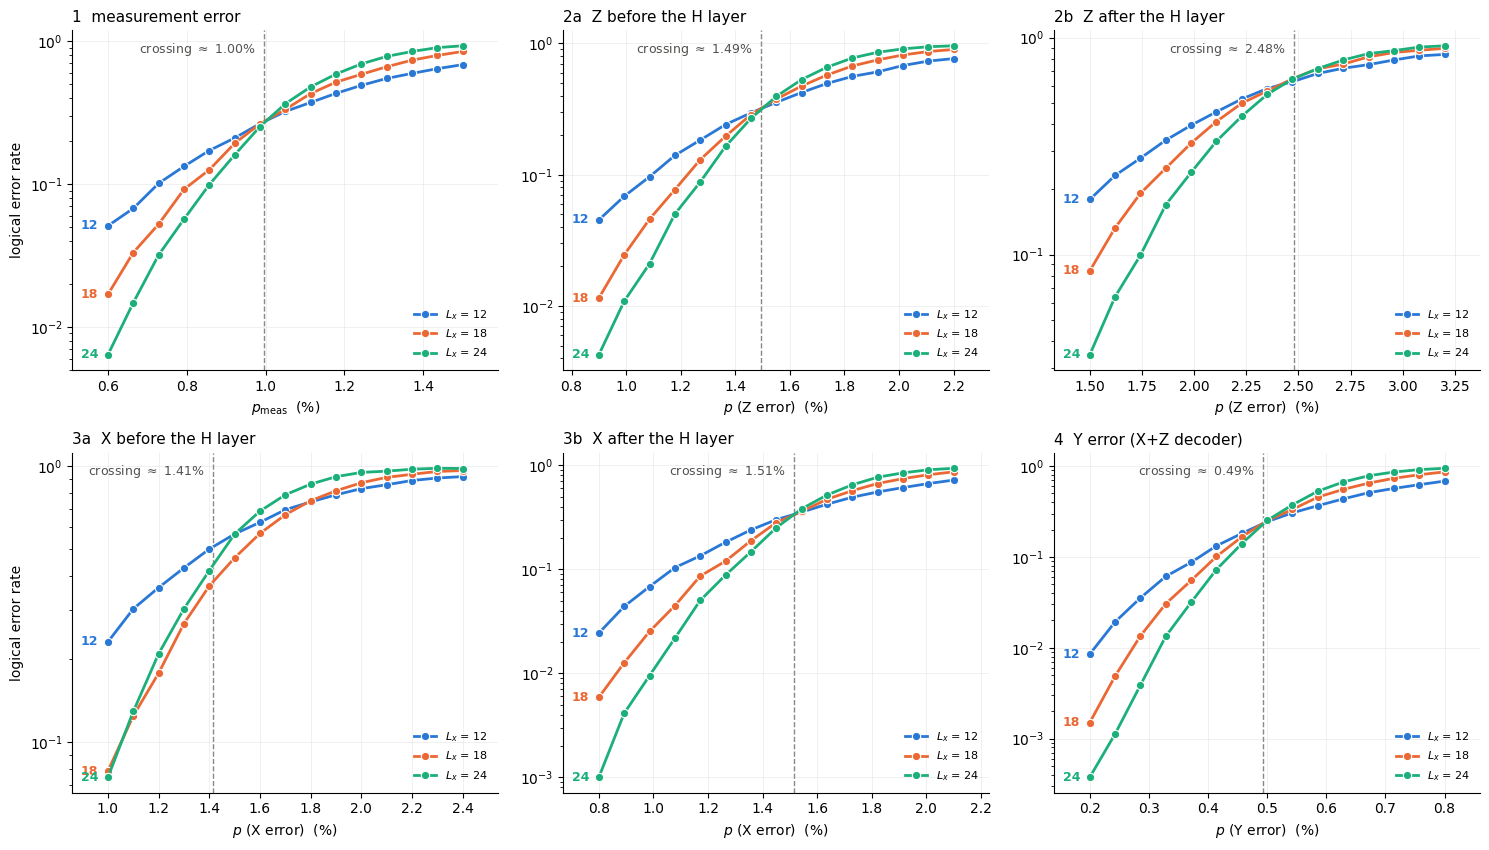

In [21]:
# categorical slots 1-3, in fixed order, one per lattice size
SERIES = {4: "#2a78d6", 6: "#eb6834", 8: "#1baf7a"}
PANELS = [("meas", "1  measurement error", "$p_\\mathrm{meas}$"),
          ("z_before", "2a  Z before the H layer", "$p$ (Z error)"),
          ("z_after", "2b  Z after the H layer", "$p$ (Z error)"),
          ("x_before", "3a  X before the H layer", "$p$ (X error)"),
          ("x_after", "3b  X after the H layer", "$p$ (X error)"),
          ("y", "4  Y error (X+Z decoder)", "$p$ (Y error)")]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.6))
for ax, (case, title, xlab) in zip(axes.ravel(), PANELS):
    ps = P_GRID[case] * 100
    for x in SIZES:
        y = results[case][x]
        ax.plot(ps, y, "-o", color=SERIES[x], linewidth=2, markersize=6,
                markeredgecolor="white", markeredgewidth=0.8, label=f"$L_x$ = {3 * x}")
        # direct label at the LEFT end, where the three curves are well separated
        # (they converge on the right, so labels there would collide)
        ax.annotate(f"{3 * x}", (ps[0], y[0]), color=SERIES[x], fontsize=9,
                    fontweight="bold", xytext=(-7, 0), textcoords="offset points",
                    ha="right", va="center")
    xc = [v for v in CROSSINGS[case] if v]
    if xc:
        mid = float(np.mean(xc)) * 100
        ax.axvline(mid, color="#8a8983", linewidth=1, linestyle="--", zorder=0)
        ax.annotate(f"crossing $\\approx$ {mid:.2f}%", (mid, 0.97),
                    xycoords=("data", "axes fraction"), xytext=(-6, 0),
                    textcoords="offset points", ha="right", va="top",
                    color="#52514e", fontsize=9)
    ax.set_yscale("log")
    ax.margins(x=0.10)
    ax.set_xlabel(xlab + "  (%)")
    ax.set_title(title, fontsize=11, loc="left")
    ax.grid(alpha=0.22, linewidth=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.legend(fontsize=8, frameon=False, loc="lower right")
for ax in axes[:, 0]:
    ax.set_ylabel("logical error rate")
plt.tight_layout()
plt.show()

### Reading the numbers

| case | noise | 12 vs 18 | 18 vs 24 | spread |
|---|---|---|---|---|
| 1  | measurement error      | 0.99% | 1.00% | 0.01 |
| 2a | `Z` before the H layer | 1.49% | 1.50% | 0.02 |
| 2b | `Z` after the H layer  | 2.40% | 2.55% | 0.15 |
| 3a | `X` before the H layer | 1.78% | 1.05% | **0.73** |
| 3b | `X` after the H layer  | 1.52% | 1.50% | 0.02 |
| 4  | `Y` (X+Z decoder)      | 0.49% | 0.50% | 0.01 |

The **spread** column -- how far a case's two pairwise crossings disagree -- is
the honest convergence indicator, and it is what decides which of these numbers
is worth quoting. Four of the six (1, 2a, 3b, 4) agree to 0.02 points or better
and have clearly settled.

**Case 4, `Y`, is the lowest at ~0.5%, and for two compounding reasons.** A `Y`
flips *both* records of its fusion, so at a given rate it corrupts twice the
syndrome a single-Pauli channel does; and because the model is not graphlike, it
is decoded on an `X`+`Z` graph that throws away the `X`-`Z` correlation inside
each error. **The true code-limited number is higher than 0.5%** -- a correlated
matcher or belief propagation would recover some of the gap. Quote it as a lower
bound, not as the code's `Y` threshold.

**Case 1 sits below the single-Pauli state-noise cases** for a counting reason
rather than a structural one: a noisy `M` corrupts each of a fusion's two records
independently, whereas a single-Pauli channel can only ever corrupt one of them
(§7's slot table), so at equal `p` measurement noise damages twice as much
syndrome.

**Cases 2a and 3b land within 0.03 of each other (1.49/1.50 and 1.52/1.50).** That is a coincidence at this
precision, not a duality: the verification cell above confirms all four
(Pauli, splice) combinations are distinct channels with different detector error
models. Two digits and 10,000 shots are simply not enough to separate them.

**Case 3a is the one not to quote.** Its two crossings disagree by 0.73 points
(1.78% vs 1.05%), which is not a noisy threshold estimate -- it is the absence of
one in this window. Reading down the `x_before` column: `Lx = 18` and `Lx = 24`
are nearly degenerate at the bottom of the range at the bottom of the range
and then *invert*, with `Lx = 24` doing steadily **worse** than `Lx = 18` from
`p` = 1.1% upward. Growing the patch from 18 to 24 stops helping against this
channel, so the two crossings are not estimating the same quantity.

Whatever limits performance against `X`-before-the-layer noise is not a
low-weight logical *representative*: all six closed forms of §6 grow with the
lattice area (weight 128 -> 288 -> 512 and 144 -> 324 -> 576, exactly 4x for a 2x
linear size). The code distance is the minimum weight over each logical's coset,
which those representatives do not expose, so that minimum is the thing to go
looking for -- and §6's closed forms are the right starting point for it. Case 2b
shows a milder version of the same drift (spread 0.15, still rising with size)
and also wants a fourth lattice size rather than more shots.

These are crossing interpolations at 8,000 shots with no finite-size-scaling fit
and no error bars. For publication numbers, redo them with more shots, a fourth
size, and a proper finite-size-scaling fit.

---
## 8. H-fusion on selected edges

### The primitive

`H_fusion(a, b)` is a Hadamard on both qubits followed by §2's plain fusion:

```
H a ; H b ; CNOT a b ; H a ; M a ; M b
```

Conjugating by `H⊗H` exchanges `X_a X_b` and `Z_a Z_b`. An H-fusion therefore
measures the same two operators as the plain fusion, with the two record names
exchanged: slot `XX` reads `ZZ`, and slot `ZZ` reads `XX`. That is the same
effect §3's Hadamard layer has on an internal edge.

### Where it goes

| step kind | crossing edge | internal edge |
|---|---|---|
| `XX` (rXX, bXX, gXX) | **H-fusion** | plain fusion |
| `ZZ` (rZZ, gZZ, bZZ) | plain fusion | **H-fusion** |

### What it does, combined with the Hadamard layer

Each fusion now carries up to two name-exchanges: one from the layer (internal
edges, every step) and one from the H-fusion. Two exchanges cancel, since
`H·H = I` on both qubits.

| step kind | edge | layer | H-fusion | net, relative to the plain hexagon code |
|---|---|---|---|---|
| `XX` | crossing | -- | exchanged | **exchanged** |
| `XX` | internal | exchanged | -- | **exchanged** |
| `ZZ` | crossing | -- | -- | unchanged |
| `ZZ` | internal | exchanged | exchanged | unchanged |

The internal/crossing distinction drops out. Every `XX`-step fusion has its
names exchanged and no `ZZ`-step fusion does. The net Hadamard pattern is
therefore exactly `Hexagon_fbqc_walkthrough.ipynb` §8: an H-fusion at every
`XX` step and nowhere else.

### Prediction

The checks keep the same supports, windows and ranks. Only the record each term
reads moves:

* **Checks:** in `CHECK_SPEC` the internal and crossing slots always disagree,
  and the crossing slot runs `ZZ, XX, XX, ZZ`. Exchanging the names on every
  `XX` step makes both slots equal in every term. **X checks read only `XX`
  records, and Z checks only `ZZ` records**, on internal and crossing edges
  alike.
* **Logicals:** `LOGICAL_SPEC` names each term's crossing slot `K`, and
  internal edges take the opposite. After the H-fusions, a term reads `K` at
  a `ZZ` step and the opposite of `K` at an `XX` step, for both edge kinds.

The cells below check all of this against the circuit:

* Stim's determinism check.
* `has_flow` on every check and every logical.
* The rank of checks plus logicals.
* Negative controls: §5/§6's unmodified tables must fail on the new circuit
  wherever they read an H-fused record.


In [31]:
def h_fusion(circuit, a, b, p_meas=0.0):
    """§2's fusion with a Hadamard on both qubits first: the two record names
    are exchanged (slot XX reads ZZ, slot ZZ reads XX)."""
    circuit.append("H", [a, b])
    fusion(circuit, a, b, p_meas)


def hfuse_rule(net, p, r, kind):
    """True iff edge p-r at a step of native `kind` gets an H-fusion:
    crossing edges on the XX steps, internal edges on the ZZ steps."""
    return net.is_internal(p, r) == (kind == "ZZ")


c_hf = stim.Circuit()
h_fusion(c_hf, 0, 1)
assert c_hf == stim.Circuit("H 0 1\nCNOT 0 1\nH 0\nM 0 1")
m = reads(pre_h=(0, 1))
print(f"H-fusion:  slot XX reads {m['rec[-2]']}   slot ZZ reads {m['rec[-1]']}")
assert m == {"rec[-2]": "ZZ", "rec[-1]": "XX"}

# what each fusion's slots read once the layer AND the H-fusion are both in place
print("\nwhat a fusion's slots read, by step kind and edge kind:")
print(f"   {'step':>4} {'edge':>8} | {'layer H':>7} {'H-fusion':>8} | slot XX reads")
for kind in ("XX", "ZZ"):
    for internal in (False, True):
        n_h = int(internal) + int(internal == (kind == "ZZ"))   # layer + H-fusion
        got = reads(pre_h=(0, 1) * n_h)["rec[-2]"]
        print(f"   {kind:>4} {('internal' if internal else 'crossing'):>8} | "
              f"{('yes' if internal else '--'):>7} {('yes' if internal == (kind == 'ZZ') else '--'):>8} | {got}")
        assert got == ("ZZ" if kind == "XX" else "XX")
print("=> exchanged on every XX-step fusion, on no ZZ-step fusion, whatever the edge kind")

# Net Hadamard pattern, per fusion, on the §4 demo circuit: layer XOR H-fusion
net_h = Counter()
for (t, colour, kind, p, r) in records:
    layer = had_self(net, p, t)
    assert layer == had_self(net, r, t), "the layer hits both ends of a fusion or neither"
    net_h[(kind, layer != hfuse_rule(net, p, r, kind))] += 1
print("\n(step kind, net Hadamard on the fusion) -> count:", dict(net_h))
assert set(net_h) == {("XX", True), ("ZZ", False)}
print("net Hadamard on every XX-step fusion and on no ZZ-step fusion: OK")


H-fusion:  slot XX reads ZZ   slot ZZ reads XX

what a fusion's slots read, by step kind and edge kind:
   step     edge | layer H H-fusion | slot XX reads
     XX crossing |      --      yes | ZZ
     XX internal |     yes       -- | ZZ
     ZZ crossing |      --       -- | XX
     ZZ internal |     yes      yes | XX
=> exchanged on every XX-step fusion, on no ZZ-step fusion, whatever the edge kind

(step kind, net Hadamard on the fusion) -> count: {('XX', True): 288, ('ZZ', False): 288}
net Hadamard on every XX-step fusion and on no ZZ-step fusion: OK


### `CHECK_SPEC_H`

The checks keep the same `(dt, edge colour)` terms as `CHECK_SPEC`. Each
internal/crossing slot pair becomes `XX/XX` in every X check and `ZZ/ZZ` in
every Z check.

`hfuse_swap` is the permutation of the outcome axis that exchanges the two
records of every H-fused fusion. It ties the two tables together: the
H-fusion circuit's checks must equal `CHECK_SPEC`'s checks with that
permutation applied. Showing this proves the explicit table and the
"same checks, records moved" statement say the same thing.


In [32]:
CHECK_SPEC_H = {(hex_colour, xz): [(dt, edge_colour, xz * 2, xz * 2)
                                   for (dt, edge_colour, _ki, _kc) in terms]
                for (hex_colour, xz), terms in CHECK_SPEC.items()}


def hfuse_swap(st, records, nmeas, hfuse=hfuse_rule):
    """Outcome-axis permutation exchanging the XX and ZZ records of every
    H-fused fusion; `rows[:, perm]` moves a row onto the H-fusion circuit."""
    perm = np.arange(nmeas)
    for (t, colour, kind, p, r), (ixx, izz) in records.items():
        if hfuse(st.net, p, r, kind):
            perm[ixx], perm[izz] = izz, ixx
    return perm


print("CHECK_SPEC_H  (each cell: internal / crossing slot)")
for (hex_colour, xz), terms in CHECK_SPEC_H.items():
    print(f"   {hex_colour:>5} {xz}: " + "   ".join(f"t={dt} {col} {ki}/{kc}"
                                                   for (dt, col, ki, kc) in terms))

circ_h, records_h, nmeas_h = build(st, hfuse=hfuse_rule)
assert records_h == records and nmeas_h == nmeas, "same fusions, same record indices"
checks_h, check_meta_h = check_rows(st, records_h, nmeas_h, spec=CHECK_SPEC_H)
perm = hfuse_swap(st, records_h, nmeas_h)
print(f"\nH-fused fusions: {sum(perm != np.arange(nmeas_h)) // 2} of {nmeas_h // 2}")
print("CHECK_SPEC_H rows == CHECK_SPEC rows with the H-fused records exchanged:",
      np.array_equal(checks_h, checks[:, perm]))
assert np.array_equal(checks_h, checks[:, perm])


CHECK_SPEC_H  (each cell: internal / crossing slot)
    blue X: t=0 red XX/XX   t=1 green XX/XX   t=3 red XX/XX   t=4 green XX/XX
    blue Z: t=3 red ZZ/ZZ   t=4 green ZZ/ZZ   t=6 red ZZ/ZZ   t=7 green ZZ/ZZ
     red X: t=4 green XX/XX   t=5 blue XX/XX   t=7 green XX/XX   t=8 blue XX/XX
     red Z: t=1 green ZZ/ZZ   t=2 blue ZZ/ZZ   t=4 green ZZ/ZZ   t=5 blue ZZ/ZZ
   green X: t=2 blue XX/XX   t=3 red XX/XX   t=5 blue XX/XX   t=6 red XX/XX
   green Z: t=5 blue ZZ/ZZ   t=6 red ZZ/ZZ   t=8 blue ZZ/ZZ   t=9 red ZZ/ZZ



H-fused fusions: 288 of 576
CHECK_SPEC_H rows == CHECK_SPEC rows with the H-fused records exchanged: True


### Verification: checks

The same checks as §5 run on the H-fusion circuit: a DEM build covering all
detectors, then `has_flow` per check. The negative control is §5's unmodified
`CHECK_SPEC` rows, which must **not** be deterministic on the new circuit.


In [33]:
def flows(circuit, nmeas, rows):
    return [circuit.has_flow(stim.Flow("1 -> " + " xor ".join(
        f"rec[{int(j) - nmeas}]" for j in np.flatnonzero(v)))) for v in rows]


probe_h = circ_h.copy()
add_detectors(probe_h, checks_h, nmeas_h)
try:
    probe_h.detector_error_model(decompose_errors=True)
    print(f"DEM built: all {probe_h.num_detectors} H-fusion detectors deterministic")
except Exception as e:
    print("DEM FAILED:", str(e).split("\n")[0])

ok_h = flows(circ_h, nmeas_h, checks_h)
ok_old = flows(circ_h, nmeas_h, checks)
tally = Counter((hc, xz, okk) for (hc, _c, xz, _cy), okk in zip(check_meta_h, ok_h))
print("\nper-check has_flow on the H-fusion circuit:")
for hc in ("red", "green", "blue"):
    print("   " + "    ".join(f"{hc:>5} {xz}: {tally[(hc, xz, True)]:3d} valid / "
                             f"{tally[(hc, xz, True)] + tally[(hc, xz, False)]:3d}" for xz in ("X", "Z")))
print(f"\nCHECK_SPEC_H: {sum(ok_h)}/{len(ok_h)} deterministic;  rank = {rank(checks_h)} "
      f"(§5: {rank(checks)})")
print(f"unmodified CHECK_SPEC on the H-fusion circuit: {sum(ok_old)}/{len(ok_old)} deterministic"
      "   <- negative control, expect 0")
assert all(ok_h) and not any(ok_old) and rank(checks_h) == rank(checks)


DEM built: all 192 H-fusion detectors deterministic



per-check has_flow on the H-fusion circuit:
     red X:  32 valid /  32      red Z:  32 valid /  32
   green X:  32 valid /  32    green Z:  32 valid /  32
    blue X:  32 valid /  32     blue Z:  32 valid /  32

CHECK_SPEC_H: 192/192 deterministic;  rank = 190 (§5: 190)
unmodified CHECK_SPEC on the H-fusion circuit: 0/192 deterministic   <- negative control, expect 0


### Verification: logicals

The logicals are §6's closed forms with the H-fused records exchanged. The
tally below shows which slot each logical's terms read, split by step kind and
edge kind, before (§6) and after (§8). It confirms the rule stated above:
after the H-fusions, the slot depends only on the step kind.

The checks match §6: each logical passes `has_flow`, and the six together
add exactly 6 dimensions to the checks.

The negative control needs one refinement. Vertical Z reads only `XX`-step
internal edges and `ZZ`-step crossing edges, which are exactly the fusions
that do *not* get an H-fusion. It is therefore unchanged, and its §6 form
stays valid. The control asserts the precise version: an unexchanged §6 form
fails **exactly** when it reads an H-fused record.


In [34]:
circ6_h, records6_h, nmeas6_h = build(st6, hfuse=hfuse_rule)
assert records6_h == records6
perm6 = hfuse_swap(st6, records6_h, nmeas6_h)
forms_h = {name: v[perm6] for name, v in forms.items()}

# which slot each term reads, keyed by (step kind, edge kind): §6 vs §8
slot_of = {}
for (t, colour, kind, p, r), (ixx, izz) in records6.items():
    ek = net.edge_kind(p, r)
    slot_of[ixx], slot_of[izz] = (kind, ek, "XX"), (kind, ek, "ZZ")
print(f"{'logical':>14}  {'step/edge':>12}   §6 slots read      ->  §8 slots read")
for name in forms:
    before = Counter(slot_of[i] for i in np.flatnonzero(forms[name]))
    after = Counter(slot_of[i] for i in np.flatnonzero(forms_h[name]))   # same record indices
    label = name
    for kind in ("XX", "ZZ"):
        for ek in ("crossing", "internal"):
            b = "+".join(s for s in ("XX", "ZZ") if before[(kind, ek, s)])
            a = "+".join(s for s in ("XX", "ZZ") if after[(kind, ek, s)])
            if b or a:
                print(f"{label:>14}  {kind + ' ' + ek:>12}   {b:<18} ->  {a}")
                label = ""

ok_h6 = flows(circ6_h, nmeas6_h, forms_h.values())
ok_old6 = flows(circ6_h, nmeas6_h, forms.values())
# a logical that reads no H-fused record is unchanged, so its §6 form stays valid
touches = [bool(np.any(v & (perm6 != np.arange(nmeas6_h)))) for v in forms.values()]
print()
for (name, v), okk, okk0, tch in zip(forms_h.items(), ok_h6, ok_old6, touches):
    print(f"   {name:>14} weight {int(v.sum()):>5}  has_flow={okk}   "
          f"touches an H-fusion: {str(tch):>5}   unexchanged §6 form: {okk0}")

checks6_h, _ = check_rows(st6, records6_h, nmeas6_h, spec=CHECK_SPEC_H)
r_checks_h = rank(checks6_h)
r_comb_h = rank(np.concatenate([checks6_h] + [v[None, :] for v in forms_h.values()]))
print(f"\nrank(checks) = {r_checks_h}, rank(checks + 6 logicals) = {r_comb_h}")
assert all(ok_h6) and r_comb_h == r_checks_h + 6
assert ok_old6 == [not tch for tch in touches], \
    "an unexchanged §6 form should fail exactly when it reads an H-fused record"
print("all 6 deterministic and independent; an unexchanged §6 form fails exactly when "
      "it touches an H-fusion: OK")


       logical     step/edge   §6 slots read      ->  §8 slots read
    Timelike X   XX crossing   ZZ                 ->  XX
                 XX internal   XX                 ->  XX
                 ZZ crossing   XX                 ->  XX
                 ZZ internal   ZZ                 ->  XX
    Timelike Z   XX crossing   XX                 ->  ZZ
                 XX internal   ZZ                 ->  ZZ
                 ZZ crossing   ZZ                 ->  ZZ
                 ZZ internal   XX                 ->  ZZ
    Vertical Z   XX internal   ZZ                 ->  ZZ
                 ZZ crossing   ZZ                 ->  ZZ
  Horizontal Z   XX crossing   XX                 ->  ZZ
                 ZZ crossing   ZZ                 ->  ZZ
                 ZZ internal   XX                 ->  ZZ
    Vertical X   XX crossing   ZZ                 ->  XX
                 XX internal   XX                 ->  XX
                 ZZ crossing   XX                 ->  XX
                 ZZ 


       Timelike X weight   144  has_flow=True   touches an H-fusion:  True   unexchanged §6 form: False
       Timelike Z weight   144  has_flow=True   touches an H-fusion:  True   unexchanged §6 form: False
       Vertical Z weight   144  has_flow=True   touches an H-fusion: False   unexchanged §6 form: True
     Horizontal Z weight   144  has_flow=True   touches an H-fusion:  True   unexchanged §6 form: False
       Vertical X weight   128  has_flow=True   touches an H-fusion:  True   unexchanged §6 form: False
     Horizontal X weight   128  has_flow=True   touches an H-fusion:  True   unexchanged §6 form: False

rank(checks) = 382, rank(checks + 6 logicals) = 388
all 6 deterministic and independent; an unexchanged §6 form fails exactly when it touches an H-fusion: OK


---
## 9. Thresholds with and without the H-fusions

Two thresholds, each measured on two circuits through **one** pipeline:

| noise | model |
|---|---|
| `p_meas` | every fusion outcome flipped independently with probability `p` (§7's case 1) |
| `p_erase` | every fusion outcome erased independently with probability `p`: replaced by a random bit, and the decoder is told which (heralded) |

The two circuits are §4's (plain fusions everywhere) and §8's (H-fusions on
the XX-step crossing edges and the ZZ-step internal edges).

**What to expect.** The thresholds should be the same, for three reasons:

1. The two circuits measure the same operators. §8 shows they differ only in
   which of a fusion's two records holds which result.
2. Both noise models treat each record independently and identically, and
   both circuits have an all-zero noiseless reference sample (checked below).
   A shot's syndrome and observable flips therefore depend only on the noise
   pattern.
3. Permuting the bits leaves an i.i.d. noise distribution unchanged.

So the two decoding problems are isomorphic, and the thresholds must agree
within shot noise. The runs below are an end-to-end check of that. §7's
`p_meas` crossings (0.99% / 1.00%) and `Hexagon_fbqc_walkthrough.ipynb`'s
erasure threshold (11.75%) serve as outside reference points.

### Method

* **Lattice sizes:** `Lx = 12, 18, 24`, each at full closure, as in §7.
* **Sampling:** each circuit is sampled once, noiselessly, per size. Both noise
  models are then applied in post-processing. They are classical operations on
  the outcome bits, so this is exact, not an approximation.
* **`p_meas` decoding:** one `pymatching` graph built from the DEM, 20,000
  shots per point.
* **`p_erase` decoding:** the same graph, with each erased outcome's edge set
  to weight 0 for that shot only. This needs every outcome to be its own edge,
  which is checked. Shots per point: 2,000 at Lx=12/18 and 1,000 at Lx=24.
  Erasure decoding is per-shot, and Lx=24 is the slow one.
* **Thresholds:** the naive pairwise crossings `12 x 18` and `18 x 24`, as in
  §7, using §7's `crossing`.
* **Runtime:** about 25 minutes for everything.


In [35]:
import time
import multiprocessing as mp
import pymatching

VARIANTS = {"§4 plain": None, "§8 H-fusion": hfuse_rule}
TH_SIZES = [4, 6, 8]                  # Lx = 12, 18, 24
P_MEAS_GRID = np.round(np.linspace(0.008, 0.012, 11), 6)
P_ERASE_GRID = np.round(np.linspace(0.100, 0.140, 11), 6)
SHOTS_MEAS = 20000
SHOTS_ERASE = {4: 2000, 6: 2000, 8: 1000}
W_REF = float(np.log((1 - 0.01) / 0.01))      # uniform edge weight; MWPM is scale-invariant


def parities(outcomes, rows, chunk=2048):
    """XOR of each row's support, 8 shots per byte (rows: (n_rows, nmeas) GF(2))."""
    idx = [np.flatnonzero(v) for v in rows]
    out = np.zeros((outcomes.shape[0], len(idx)), dtype=np.uint8)
    for s0 in range(0, outcomes.shape[0], chunk):
        packed = np.packbits(outcomes[s0:s0 + chunk], axis=0)
        res = np.stack([np.bitwise_xor.reduce(packed[:, i], axis=1) for i in idx], axis=1)
        out[s0:s0 + chunk] = np.unpackbits(res, axis=0, count=min(chunk, outcomes.shape[0] - s0))
    return out


_th = {}

def th_structure(x_max, variant):
    """Checks, logicals, matcher and a noiseless sample source for one
    (size, circuit) pair."""
    key = (x_max, variant)
    if key in _th:
        return _th[key]
    t0 = time.time()
    hfuse = VARIANTS[variant]
    net_ = HexLattice(x_max, x_max)
    st_ = Spacetime(net_, n_cycles=x_max)
    assert internal_crossing_tables(net_, 0)[0] == NATIVE_OF_X
    assert internal_crossing_tables(net_, 1)[0] == NATIVE_OF_Y
    clean, recs, nm = build(st_, hfuse=hfuse)
    ch, _ = check_rows(st_, recs, nm, spec=CHECK_SPEC if hfuse is None else CHECK_SPEC_H)
    lg = np.array(list(build_logicals(net_, st_, recs, nm).values()), np.uint8)
    if hfuse is not None:
        lg = lg[:, hfuse_swap(st_, recs, nm, hfuse)]

    noisy, _, _ = build(st_, p_meas=0.01, hfuse=hfuse)
    add_detectors(noisy, ch, nm)
    for k, v in enumerate(lg):
        noisy.append("OBSERVABLE_INCLUDE", [stim.target_rec(int(i) - nm) for i in np.flatnonzero(v)], k)
    m = pymatching.Matching.from_detector_error_model(noisy.detector_error_model(decompose_errors=True))

    # erasure reweighting needs outcome <-> edge to be one-to-one
    edge_of, seen = {}, set()
    for i in range(nm):
        pair = tuple(int(d) for d in np.flatnonzero(ch[:, i]))
        assert len(pair) == 2 and pair not in seen, (i, pair)
        seen.add(pair)
        edge_of[i] = (pair[0], pair[1], frozenset(int(k) for k in np.flatnonzero(lg[:, i])))
    assert m.num_edges == nm, (m.num_edges, nm)

    _th[key] = dict(clean=clean, checks=ch, logs=lg, nmeas=nm, matcher=m, edge_of=edge_of)
    print(f"  [{variant:>11} Lx={3 * x_max}: nmeas={nm} detectors={len(ch)} "
          f"edges={m.num_edges}  ({time.time() - t0:.0f}s)]", flush=True)
    return _th[key]


def clean_sample(S, shots, seed):
    return S['clean'].compile_sampler(seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)


# skip_reference_sample=True assumes an all-zero noiseless reference -- checked:
for variant in VARIANTS:
    S = th_structure(4, variant)
    print(f"  {variant:>11}: noiseless reference sample all-zero: "
          f"{not S['clean'].reference_sample().any()}")


  [   §4 plain Lx=12: nmeas=2304 detectors=384 edges=2304  (8s)]


     §4 plain: noiseless reference sample all-zero: True


  [§8 H-fusion Lx=12: nmeas=2304 detectors=384 edges=2304  (9s)]


  §8 H-fusion: noiseless reference sample all-zero: True


In [36]:
_pool_state = {}


def _decode_chunk(args):
    """Forked worker: decode a chunk of shots, zeroing erased edges per shot.
    The Matching is inherited copy-on-write (it cannot be pickled)."""
    dets, erased = args
    m, edge_of, n_obs = _pool_state['m'], _pool_state['edge_of'], _pool_state['n_obs']
    pred = np.zeros((dets.shape[0], n_obs), dtype=np.uint8)
    for s in range(dets.shape[0]):
        touched = np.flatnonzero(erased[s]) if erased is not None else ()
        for i in touched:
            u, v, f = edge_of[int(i)]
            m.add_edge(u, v, weight=0.0, fault_ids=set(f), merge_strategy="replace")
        pred[s] = m.decode(dets[s])
        for i in touched:
            u, v, f = edge_of[int(i)]
            m.add_edge(u, v, weight=W_REF, fault_ids=set(f), merge_strategy="replace")
    return pred


def decode(S, dets, erased=None, n_workers=4):
    if erased is None:                             # no reweighting: batch decode
        _pool_state.update(m=S['matcher'])
        chunks = np.array_split(dets, n_workers)
        with mp.get_context("fork").Pool(n_workers) as pool:
            return np.concatenate(pool.map(_batch_worker, chunks))
    _pool_state.update(m=S['matcher'], edge_of=S['edge_of'], n_obs=len(S['logs']))
    idx = np.array_split(np.arange(dets.shape[0]), n_workers)
    with mp.get_context("fork").Pool(n_workers) as pool:
        return np.concatenate(pool.map(_decode_chunk, [(dets[i], erased[i]) for i in idx]))


def _batch_worker(chunk):
    return _pool_state['m'].decode_batch(chunk)


def failure_rate(S, outcomes, erased=None):
    dets, obs = parities(outcomes, S['checks']), parities(outcomes, S['logs'])
    return float(np.any(decode(S, dets, erased) != obs, axis=1).mean())


def sweep(x_max, variant, noise, ps, seed=2025):
    """Logical failure rate vs p for one (size, circuit, noise model)."""
    S = th_structure(x_max, variant)
    shots = SHOTS_MEAS if noise == "meas" else SHOTS_ERASE[x_max]
    raw = clean_sample(S, shots, seed)
    rates = []
    for j, p in enumerate(ps):
        rng = np.random.default_rng((seed, x_max, j))
        hit = rng.random(raw.shape, dtype=np.float32) < p
        if noise == "meas":
            rates.append(failure_rate(S, raw ^ hit.astype(np.uint8)))
        else:
            repl = rng.integers(0, 2, size=raw.shape, dtype=np.uint8)
            rates.append(failure_rate(S, np.where(hit, repl, raw), erased=hit))
    return np.array(rates)


# the parallel batch/erasure decode must match a plain single-process decode
S = th_structure(4, "§8 H-fusion")
raw = clean_sample(S, 400, 1)
rng = np.random.default_rng(1)
hit = rng.random(raw.shape) < 0.12
out = np.where(hit, rng.integers(0, 2, size=raw.shape, dtype=np.uint8), raw)
d = parities(out, S['checks'])
_pool_state.update(m=S['matcher'], edge_of=S['edge_of'], n_obs=len(S['logs']))
same_e = np.array_equal(decode(S, d, hit), _decode_chunk((d, hit)))
same_m = np.array_equal(decode(S, d), S['matcher'].decode_batch(d))
print("parallel decode == single-process decode:  erasure", same_e, "  batch", same_m)
assert same_e and same_m


parallel decode == single-process decode:  erasure True   batch True


In [37]:
P_GRIDS = {"meas": P_MEAS_GRID, "erase": P_ERASE_GRID}
th_results = {}
t_all = time.time()
for noise, ps in P_GRIDS.items():
    for variant in VARIANTS:
        for x in TH_SIZES:
            t0 = time.time()
            th_results[(noise, variant, x)] = sweep(x, variant, noise, ps)
            print(f"  {noise:>5} {variant:>11} Lx={3 * x}: {len(ps)} points "
                  f"({time.time() - t0:.0f}s)", flush=True)
print(f"\ntotal: {time.time() - t_all:.0f}s")

for noise, ps in P_GRIDS.items():
    print(f"\n{noise}: logical failure rate (any of 6 observables)")
    print(f"   {'p':<8}" + "".join(f"{v[:11] + ' ' + str(3 * x):>17}"
                                   for v in VARIANTS for x in TH_SIZES))
    for i, p in enumerate(ps):
        print(f"   {p:<8.4f}" + "".join(f"{th_results[(noise, v, x)][i]:>17.4f}"
                                       for v in VARIANTS for x in TH_SIZES))


   meas    §4 plain Lx=12: 11 points (4s)


  [   §4 plain Lx=18: nmeas=7776 detectors=1296 edges=7776  (28s)]


   meas    §4 plain Lx=18: 11 points (43s)


  [   §4 plain Lx=24: nmeas=18432 detectors=3072 edges=18432  (66s)]


   meas    §4 plain Lx=24: 11 points (107s)


...

  erase    §4 plain Lx=24: 11 points (198s)


  erase §8 H-fusion Lx=12: 11 points (17s)


  erase §8 H-fusion Lx=18: 11 points (79s)


  erase §8 H-fusion Lx=24: 11 points (189s)



total: 958s

meas: logical failure rate (any of 6 observables)
   p             §4 plain 12      §4 plain 18      §4 plain 24   §8 H-fusion 12   §8 H-fusion 18   §8 H-fusion 24
   0.0080             0.1356           0.0930           0.0633           0.1341           0.0899           0.0628
   0.0084             0.1623           0.1193           0.0890           0.1592           0.1197           0.0891
   0.0088             0.1872           0.1559           0.1197           0.1800           0.1487           0.1245
   0.0092             0.2195           0.1910           0.1693           0.2149           0.1921           0.1675
   0.0096             0.2497           0.2369           0.2152           0.2465           0.2382           0.2182
   0.0100             0.2842           0.2786           0.2740           0.2813           0.2749           0.2761
   0.0104             0.3134           0.3304           0.3455           0.3118           0.3310           0.3376
   0.0108             0.

In [38]:
TH_CROSS = {}
print(f"{'noise':>6} {'circuit':>12}  {'12 vs 18':>9} {'18 vs 24':>9}   mean")
for noise, ps in P_GRIDS.items():
    for variant in VARIANTS:
        xs = [crossing(ps, th_results[(noise, variant, TH_SIZES[i])],
                       th_results[(noise, variant, TH_SIZES[i + 1])]) for i in (0, 1)]
        TH_CROSS[(noise, variant)] = xs
        found = [x for x in xs if x is not None]
        cells_ = "".join(f"{(f'{x * 100:.3f}%' if x is not None else '--'):>10}" for x in xs)
        mean = f"{np.mean(found) * 100:.3f}%" if found else "--"
        print(f"{noise:>6} {variant:>12} {cells_}   {mean}")

print()
for noise in P_GRIDS:
    a, b = (np.mean([x for x in TH_CROSS[(noise, v)] if x is not None]) for v in VARIANTS)
    print(f"{noise:>6}: H-fusion - plain = {(b - a) * 100:+.3f} percentage points")
print("\nreference: §7 p_meas crossings 0.99% / 1.00%;  "
      "Hexagon_fbqc_walkthrough p_erase threshold 11.75%")


 noise      circuit   12 vs 18  18 vs 24   mean
  meas     §4 plain     1.010%    1.009%   1.010%
  meas  §8 H-fusion     1.010%    0.998%   1.004%
 erase     §4 plain    11.932%   11.796%   11.864%
 erase  §8 H-fusion    11.809%   11.858%   11.833%

  meas: H-fusion - plain = -0.006 percentage points
 erase: H-fusion - plain = -0.031 percentage points

reference: §7 p_meas crossings 0.99% / 1.00%;  Hexagon_fbqc_walkthrough p_erase threshold 11.75%


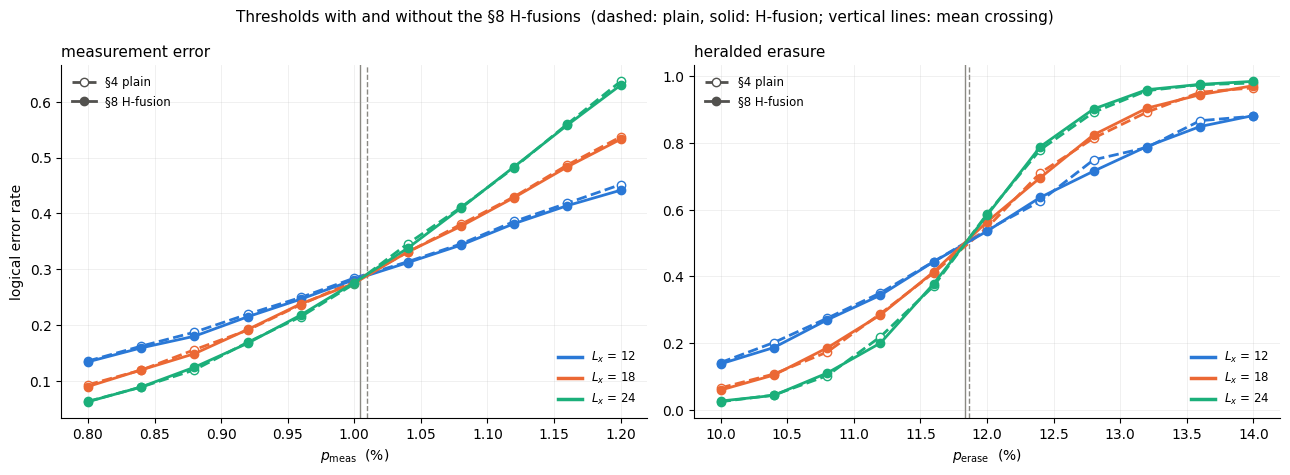

In [39]:
SERIES = {4: "#2a78d6", 6: "#eb6834", 8: "#1baf7a"}   # same per-size colours as §7
STYLE = {"§4 plain": dict(ls="--", mfc="white"), "§8 H-fusion": dict(ls="-")}
TITLES = {"meas": ("measurement error", "$p_\\mathrm{meas}$"),
          "erase": ("heralded erasure", "$p_\\mathrm{erase}$")}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, noise in zip(axes, P_GRIDS):
    ps = P_GRIDS[noise] * 100
    for variant in VARIANTS:
        for x in TH_SIZES:
            ax.plot(ps, th_results[(noise, variant, x)], marker="o", color=SERIES[x],
                    linewidth=2, markersize=6, **STYLE[variant])
        found = [v for v in TH_CROSS[(noise, variant)] if v is not None]
        if found:
            ax.axvline(np.mean(found) * 100, color="#8a8983", linewidth=1,
                       ls=STYLE[variant]["ls"], zorder=0)
    title, xlab = TITLES[noise]
    ax.set_title(title, fontsize=11, loc="left")
    ax.set_xlabel(xlab + "  (%)")
    ax.grid(alpha=0.22, linewidth=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    sizes_leg = ax.legend(handles=[plt.Line2D([], [], color=SERIES[x], lw=2.5, label=f"$L_x$ = {3 * x}")
                                   for x in TH_SIZES], fontsize=8.5, frameon=False, loc="lower right")
    ax.add_artist(sizes_leg)
    ax.legend(handles=[plt.Line2D([], [], color="#52514e", marker="o", lw=2, label=v, **STYLE[v])
                       for v in VARIANTS], fontsize=8.5, frameon=False, loc="upper left")
axes[0].set_ylabel("logical error rate")
fig.suptitle("Thresholds with and without the §8 H-fusions  (dashed: plain, solid: H-fusion; "
             "vertical lines: mean crossing)", fontsize=11)
plt.tight_layout()
plt.show()


### Result

| noise | §4 plain: 12 vs 18 / 18 vs 24 | §8 H-fusion: 12 vs 18 / 18 vs 24 | difference of means |
|---|---|---|---|
| `p_meas`  | 1.010% / 1.009% | 1.010% / 0.998% | -0.006 points |
| `p_erase` | 11.93% / 11.80% | 11.81% / 11.86% | -0.03 points |

The H-fusions leave both thresholds where they were. Both shifts are smaller
than the spread between each circuit's own two crossings, so they are shot
noise. That is what the record-relabelling argument requires.

* The `p_meas` crossings match §7's (0.99% / 1.00%), which were obtained with
  a different sampler (Stim's noisy detector sampler, not post-processed
  flips).
* The `p_erase` crossings sit at about 11.8-11.9%, consistent with the plain
  hexagon code's 11.75% in `Hexagon_fbqc_walkthrough.ipynb`.

These are naive crossings without a finite-size-scaling fit, as in §7.


---
## 10. Biased measurement error

§9's `p_meas` flips both outcomes of every fusion at the same rate `p`. Here a
bias parameter `δ` moves that noise between the two **measurements** a fusion
makes, keeping the total fixed:

| fusion outcome | flipped with probability |
|---|---|
| `X_a X_b` | `2 (1 - δ) p` |
| `Z_a Z_b` | `2 δ p` |

So `δ = 0` flips only `XX` outcomes (at `2p`), `δ = 1` only `ZZ` outcomes, and
**`δ = 0.5` is exactly §9's model**, `p` on each outcome. Every threshold in
§10-§13 is therefore directly comparable with §9's: at `δ = 0.5` it should be
§9's `p_meas ≈ 1.0%`.

**Which outcome is which.** The operators are those measured on the qubits *as
they arrive at the fusion*, i.e. after §3's Hadamard layer, which is part of the
resource state. A plain fusion reports `X_a X_b` in slot `XX` (`rec[-2]`); an
H-fusion (§8) measures the same two operators and reports `X_a X_b` in slot `ZZ`
(`rec[-1]`). So for §4 plain the bias is exactly slot `XX` vs slot `ZZ`, and on
§8's H-fused fusions it follows the operator into the other slot.

### Why §9's equivalence still holds

§9's argument: the §8 circuit is §4 plain with the H-fused fusions' records
relabelled, and its noise treated every record alike. Here the noise is attached
to the operators, and the relabelling moves each operator's outcome together with
its noise, so **the two circuits are the same decoding problem at every `δ`**.
Their curves must agree to within shot noise; this checks the bookkeeping rather
than adding a result. (The H-fusions would matter if the noise belonged to the
record slot, e.g. one detector noisier than the other whatever it measures. That
is not the model used here.)

### Prediction for §4 plain

Every check mixes outcomes (§5: crossing `ZZ, XX, XX, ZZ`, internal the
opposite). `δ = 0` flips exactly the records §7's case 2b flips, and `δ = 1`
exactly those of case 3b. Here those records flip at `2p`; in §7 they flip at
`2x(1-x)` for a per-qubit rate `x`. So §7's crossings predict thresholds near
`p ≈ x(1-x) ≈ 2.3-2.5%` at `δ = 0` (2b) and about `1.5%` at `δ = 1` (3b), both
above `δ = 0.5`.

### Method

* Same circuits, sizes, noiseless sampling and post-processed flips as §9.
* **Decoder: bias-aware.** One matcher per `(δ, p)` from the check matrix,
  with weight `ln((1 - q)/q)` on each record's edge, `q` being that outcome's
  flip probability (floored at `1e-6`, so a noiseless outcome gets a large finite
  weight). At uniform weights this matcher differs from §9's only by tie-breaking
  between equal-weight matchings, which is checked below.
* Fixed `p_meas = 0.5%, 0.8%, 1.2%`; `δ` from 0 to 1 in steps of 1/8; 20,000
  shots per point.

In [17]:
BIAS_DELTAS = {"meas": np.round(np.linspace(0, 1, 9), 4), "erase": np.round(np.linspace(0, 1, 5), 4)}
BIAS_P = {"meas": [0.005, 0.008, 0.012], "erase": [0.06, 0.09, 0.12]}
Q_FLOOR = 1e-6


_xx_mask = {}


def xx_outcome_mask(x_max, variant):
    """True where a record holds its fusion's X_aX_b outcome, for the qubits as they arrive
    at the fusion (after §3's layer): slot XX of a plain fusion, slot ZZ of an H-fusion (§8)."""
    key = (x_max, variant)
    if key not in _xx_mask:
        hfuse = VARIANTS[variant]
        net_ = HexLattice(x_max, x_max)
        _, recs, nm = build(Spacetime(net_, n_cycles=x_max), hfuse=hfuse)   # th_structure's record order
        m = np.zeros(nm, dtype=bool)
        for (t, colour, kind, p, r), (ixx, izz) in recs.items():
            m[izz if (hfuse is not None and hfuse(net_, p, r, kind)) else ixx] = True
        _xx_mask[key] = m
    return _xx_mask[key]


def outcome_rates(x_max, variant, p, delta):
    """Per-record noise rate: 2 (1 - delta) p on X_aX_b outcomes, 2 delta p on Z_aZ_b outcomes,
    so delta = 0.5 puts p on both -- §9's model."""
    return np.where(xx_outcome_mask(x_max, variant), 2 * (1 - delta) * p, 2 * delta * p)


def biased_matcher(S, q):
    """Matcher with each record's edge weighted by its own flip rate q."""
    w = np.log((1 - q) / np.maximum(q, Q_FLOOR))
    return pymatching.Matching.from_check_matrix(S['checks'], weights=w, faults_matrix=S['logs'])


def bias_sweep(x_max, variant, noise, p, deltas, seed=2026):
    """Logical failure rate vs delta at fixed p, for one (size, circuit, noise model)."""
    S = th_structure(x_max, variant)
    shots = SHOTS_MEAS if noise == "meas" else SHOTS_ERASE[x_max]
    raw = clean_sample(S, shots, seed)
    rates = []
    for j, delta in enumerate(deltas):
        q = outcome_rates(x_max, variant, p, delta)
        rng = np.random.default_rng((seed, x_max, int(round(p * 1e6)), j))
        hit = rng.random(raw.shape, dtype=np.float32) < q.astype(np.float32)
        if noise == "meas":
            rates.append(failure_rate(dict(S, matcher=biased_matcher(S, q)), raw ^ hit.astype(np.uint8)))
        else:
            repl = rng.integers(0, 2, size=raw.shape, dtype=np.uint8)
            rates.append(failure_rate(S, np.where(hit, repl, raw), erased=hit))
    return np.array(rates)


# the mask relies on: slot XX = even record, slot ZZ = the next one; a plain fusion reports
# X_aX_b in slot XX and an H-fusion in slot ZZ (stim flows, §2 and §8)
_st = Spacetime(HexLattice(4, 4), n_cycles=4)
_, _recs, _ = build(_st)
assert all(ixx % 2 == 0 and izz == ixx + 1 for ixx, izz in _recs.values())
assert reads() == {"rec[-2]": "XX", "rec[-1]": "ZZ"} and reads(pre_h=(0, 1)) == {"rec[-2]": "ZZ", "rec[-1]": "XX"}
print("XX slot = even record index, ZZ slot = the next one; X_aX_b is slot XX (plain) / slot ZZ (H-fusion): OK")
for variant in VARIANTS:
    m = xx_outcome_mask(4, variant)
    print(f"  {variant:>11}: X_aX_b outcome in slot XX at {int(m[0::2].sum())} fusions, in slot ZZ at {int(m[1::2].sum())}")

# at uniform weights the bias-aware matcher may break ties differently from §9's,
# but must always find a matching of the same weight
for variant in VARIANTS:
    S = th_structure(4, variant)
    m_bias = biased_matcher(S, np.full(S['nmeas'], 0.01))
    raw = clean_sample(S, 2000, 3)
    d = parities(raw ^ (np.random.default_rng(3).random(raw.shape) < 0.012).astype(np.uint8), S['checks'])
    n_diff = n_wdiff = 0
    for s in range(d.shape[0]):
        a, wa = S['matcher'].decode(d[s], return_weight=True)
        b, wb = m_bias.decode(d[s], return_weight=True)
        n_diff += not np.array_equal(a, b)
        n_wdiff += not np.isclose(wa, wb)
    print(f"  {variant:>11}: predictions differ on {n_diff}/{d.shape[0]} shots, "
          f"matching weight differs on {n_wdiff}")
    assert n_wdiff == 0
print("bias-aware matcher at uniform weights == §9 matcher up to equal-weight ties: OK")

XX slot = even record index, ZZ slot = the next one; X_aX_b is slot XX (plain) / slot ZZ (H-fusion): OK


     §4 plain: X_aX_b outcome in slot XX at 1152 fusions, in slot ZZ at 0


  §8 H-fusion: X_aX_b outcome in slot XX at 576 fusions, in slot ZZ at 576
     §4 plain: predictions differ on 247/2000 shots, matching weight differs on 0


  §8 H-fusion: predictions differ on 276/2000 shots, matching weight differs on 0
bias-aware matcher at uniform weights == §9 matcher up to equal-weight ties: OK


In [18]:
bias_results = {}
t_all = time.time()
for p in BIAS_P["meas"]:
    for variant in VARIANTS:
        for x in TH_SIZES:
            t0 = time.time()
            bias_results[("meas", variant, x, p)] = bias_sweep(x, variant, "meas", p, BIAS_DELTAS["meas"])
            print(f"  meas p={p:.3f} {variant:>11} Lx={3 * x}: ({time.time() - t0:.0f}s)", flush=True)
print(f"\ntotal: {time.time() - t_all:.0f}s")


def print_bias_table(noise):
    deltas = BIAS_DELTAS[noise]
    for p in BIAS_P[noise]:
        print(f"\n{noise}, p = {p * 100:.1f}%: logical failure rate (any of 6 observables)")
        print(f"   {'δ':<6}" + "".join(f"{v[:11] + ' ' + str(3 * x):>17}"
                                     for v in VARIANTS for x in TH_SIZES))
        for i, d in enumerate(deltas):
            print(f"   {d:<6.3f}" + "".join(f"{bias_results[(noise, v, x, p)][i]:>17.4f}"
                                         for v in VARIANTS for x in TH_SIZES))


print_bias_table("meas")

  meas p=0.005    §4 plain Lx=12: (3s)


  [   §4 plain Lx=18: nmeas=7776 detectors=1296 edges=7776  (29s)]


  meas p=0.005    §4 plain Lx=18: (54s)


  [   §4 plain Lx=24: nmeas=18432 detectors=3072 edges=18432  (71s)]


  meas p=0.005    §4 plain Lx=24: (132s)


...

  meas p=0.012    §4 plain Lx=24: (41s)


  meas p=0.012 §8 H-fusion Lx=12: (4s)


  meas p=0.012 §8 H-fusion Lx=18: (15s)


  meas p=0.012 §8 H-fusion Lx=24: (39s)



total: 603s

meas, p = 0.5%: logical failure rate (any of 6 observables)
   δ           §4 plain 12      §4 plain 18      §4 plain 24   §8 H-fusion 12   §8 H-fusion 18   §8 H-fusion 24
   0.000            0.0019           0.0003           0.0000           0.0021           0.0001           0.0000
   0.125            0.0071           0.0008           0.0000           0.0073           0.0007           0.0001
   0.250            0.0115           0.0031           0.0004           0.0118           0.0021           0.0006
   0.375            0.0157           0.0026           0.0008           0.0166           0.0043           0.0011
   0.500            0.0237           0.0061           0.0015           0.0232           0.0059           0.0014
   0.625            0.0205           0.0056           0.0012           0.0214           0.0053           0.0012
   0.750            0.0166           0.0031           0.0004           0.0164           0.0032           0.0004
   0.875            0.0115    

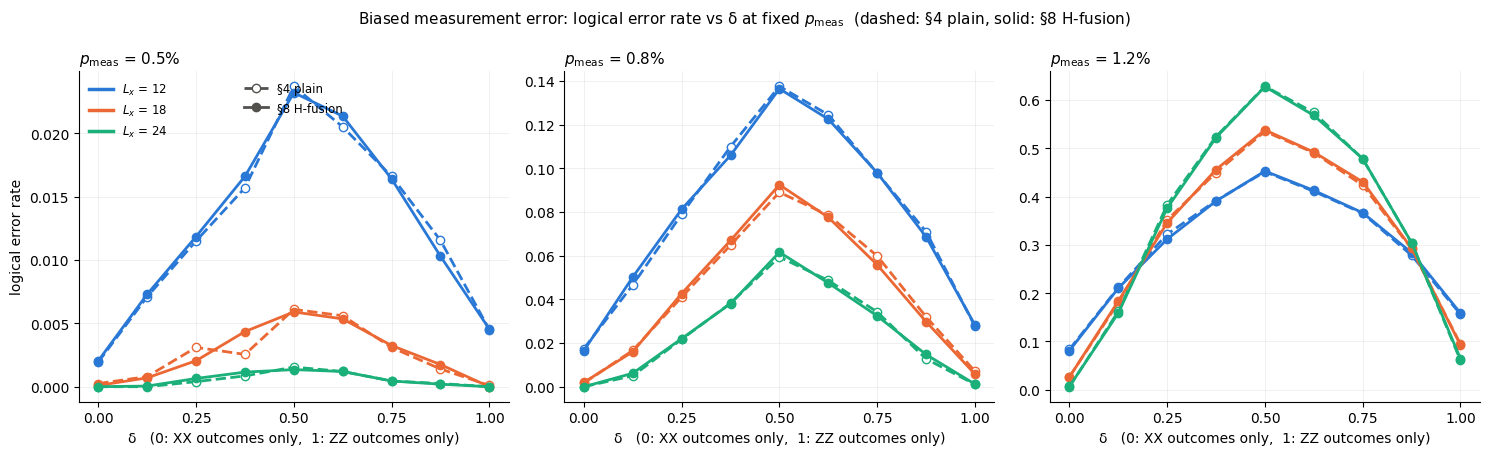

In [19]:
SERIES = {4: "#2a78d6", 6: "#eb6834", 8: "#1baf7a"}   # same per-size colours as §7 and §9
STYLE = {"§4 plain": dict(ls="--", mfc="white"), "§8 H-fusion": dict(ls="-")}


def plot_bias(noise, xlab):
    deltas = BIAS_DELTAS[noise]
    fig, axes = plt.subplots(1, len(BIAS_P[noise]), figsize=(15, 4.6))
    for ax, p in zip(axes, BIAS_P[noise]):
        for variant in VARIANTS:
            for x in TH_SIZES:
                ax.plot(deltas, bias_results[(noise, variant, x, p)], marker="o", color=SERIES[x],
                        linewidth=2, markersize=6, **STYLE[variant])
        ax.set_title(f"{xlab} = {p * 100:.1f}%", fontsize=11, loc="left")
        ax.set_xlabel("δ   (0: XX outcomes only,  1: ZZ outcomes only)")
        ax.set_xticks(np.linspace(0, 1, 5))
        ax.grid(alpha=0.22, linewidth=0.6)
        ax.set_axisbelow(True)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    axes[0].set_ylabel("logical error rate")
    sizes_leg = axes[0].legend(handles=[plt.Line2D([], [], color=SERIES[x], lw=2.5, label=f"$L_x$ = {3 * x}")
                                        for x in TH_SIZES], fontsize=8.5, frameon=False, loc="upper left")
    axes[0].add_artist(sizes_leg)
    axes[0].legend(handles=[plt.Line2D([], [], color="#52514e", marker="o", lw=2, label=v, **STYLE[v])
                            for v in VARIANTS], fontsize=8.5, frameon=False, loc="upper center")
    return fig


plot_bias("meas", "$p_\\mathrm{meas}$")
plt.suptitle("Biased measurement error: logical error rate vs δ at fixed $p_\\mathrm{meas}$  "
             "(dashed: §4 plain, solid: §8 H-fusion)", fontsize=11)
plt.tight_layout()
plt.show()

### Result

**The two circuits agree at every `δ`**, to within shot noise, as §10 argued.
At Lx = 24, `p = 0.8%`: 0.01% vs 0.01% at `δ = 0`, 5.95% vs 6.16% at `δ = 0.5`,
and 0.11% vs 0.13% at `δ = 1` (§4 plain vs §8 H-fusion). At `δ = 0.5` (§9's
unbiased model) both improve with size below §9's threshold of about 1.0% and get
worse above it. So everything below holds for both circuits.

* **§4 plain is best at the ends.** Every `δ` improves with size at 0.5% and
  0.8%. At 1.2%, above the `δ = 0.5` threshold, both ends still improve
  (`δ = 0`: 8.4 -> 2.7 -> 0.63%; `δ = 1`: 15.6 -> 9.5 -> 6.1%), and so does
  `δ = 0.125`, while `0.25 <= δ <= 0.75` gets worse. The crossings sit near
  `δ = 0.15` and `0.85`.
* **It is not symmetric in `δ`:** `δ = 0` beats `δ = 1` at every `p`. That is
  §7's ordering: `δ = 0` is case 2b's decoding problem and `δ = 1` is case 3b's,
  and 2b has the higher threshold.

§12 turns these fixed-`p` cuts into a threshold for each `δ`.

---
## 11. Biased erasure

The same split for §9's heralded erasure: each fusion's `XX` outcome is erased
with probability `2 (1 - δ) p` and its `ZZ` outcome with `2 δ p` (slot `XX` / slot
`ZZ` for a plain fusion, the other way round for an H-fusion, as in §10), so
`δ = 0.5` is §9's `p_erase`. An erased record is replaced by a random bit and the
decoder is told which.

The decoder is §9's unchanged: each erased record's edge is set to weight 0 for
that shot. The edges that are not erased never carry an error in this model, so
their weight does not need to know about the bias.

**What to expect** follows §10: the two circuits are the same decoding problem,
so their curves should agree to within shot noise. Each sector sees both kinds of
outcome, so the bias is shared between the sectors.

Fixed `p_erase = 6%, 9%, 12%`; `δ = 0, 1/4, 1/2, 3/4, 1`; §9's shot counts
(2,000 at Lx=12/18, 1,000 at Lx=24). Erasure decoding is per-shot, so this is
the slow sweep.

In [20]:
t_all = time.time()
for p in BIAS_P["erase"]:
    for variant in VARIANTS:
        for x in TH_SIZES:
            t0 = time.time()
            bias_results[("erase", variant, x, p)] = bias_sweep(x, variant, "erase", p, BIAS_DELTAS["erase"])
            print(f"  erase p={p:.2f} {variant:>11} Lx={3 * x}: ({time.time() - t0:.0f}s)", flush=True)
print(f"\ntotal: {time.time() - t_all:.0f}s")

print_bias_table("erase")

  erase p=0.06    §4 plain Lx=12: (5s)


  erase p=0.06    §4 plain Lx=18: (17s)


  erase p=0.06    §4 plain Lx=24: (20s)


  erase p=0.06 §8 H-fusion Lx=12: (4s)


  erase p=0.06 §8 H-fusion Lx=18: (15s)


...

  erase p=0.12    §4 plain Lx=24: (34s)


  erase p=0.12 §8 H-fusion Lx=12: (7s)


  erase p=0.12 §8 H-fusion Lx=18: (29s)


  erase p=0.12 §8 H-fusion Lx=24: (45s)



total: 317s

erase, p = 6.0%: logical failure rate (any of 6 observables)
   δ           §4 plain 12      §4 plain 18      §4 plain 24   §8 H-fusion 12   §8 H-fusion 18   §8 H-fusion 24
   0.000            0.0005           0.0000           0.0000           0.0015           0.0000           0.0000
   0.250            0.0000           0.0000           0.0000           0.0005           0.0000           0.0000
   0.500            0.0005           0.0000           0.0000           0.0005           0.0000           0.0000
   0.750            0.0000           0.0000           0.0000           0.0005           0.0000           0.0000
   1.000            0.0000           0.0000           0.0000           0.0005           0.0000           0.0000

erase, p = 9.0%: logical failure rate (any of 6 observables)
   δ           §4 plain 12      §4 plain 18      §4 plain 24   §8 H-fusion 12   §8 H-fusion 18   §8 H-fusion 24
   0.000            0.0320           0.0030           0.0000           0.0260  

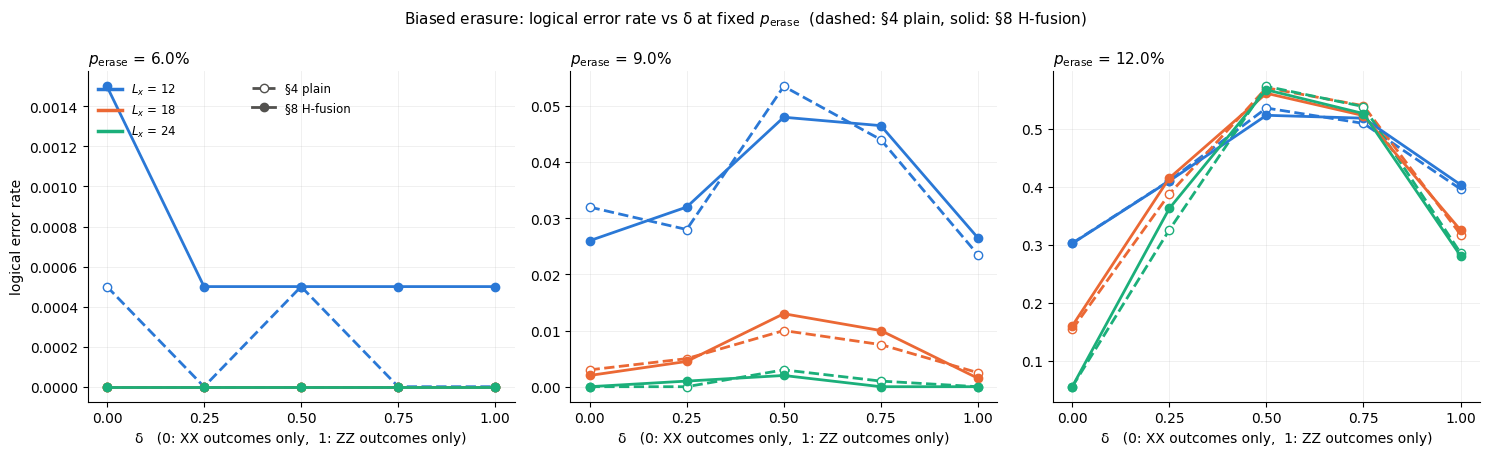

In [21]:
plot_bias("erase", "$p_\\mathrm{erase}$")
plt.suptitle("Biased erasure: logical error rate vs δ at fixed $p_\\mathrm{erase}$  "
             "(dashed: §4 plain, solid: §8 H-fusion)", fontsize=11)
plt.tight_layout()
plt.show()

### Result

The pattern is §10's:

* **The circuits agree at every `δ`** (at 12%, Lx = 24: 5.5% vs 5.5% at
  `δ = 0`, 57.4% vs 56.8% at `δ = 0.5`, 28.6% vs 28.1% at `δ = 1`; §4 plain vs
  §8 H-fusion).
* **`δ = 0.5` (§9's model):** 53.7 / 57.2 / 57.4% at 12%, rising slowly with size,
  so 12% is just above threshold, consistent with §9's 11.85%.
* **§4 plain improves with size at every `δ` at 6% and 9%.** At 12% the ends
  still improve (`δ = 0`: 30.3 -> 15.4 -> 5.5%; `δ = 1`: 39.7 -> 31.8 -> 28.6%),
  and so does `δ = 0.25`, while `δ = 0.5` and `0.75` do not. `δ = 0` again beats
  `δ = 1`.

Shot counts are §9's (2,000 / 2,000 / 1,000), so an entry of 0 means fewer than
about one failure in a thousand, and the small rates at 6% and 9% are only good
to a factor of a few.

---
## 12. Measurement threshold vs `δ`

§10 cut the problem at fixed `p_meas`. Here the cut is the other way: for each
`δ` the whole `p_meas` sweep is redone and its threshold found, giving
`p_th(δ)` for both circuits. The noise model and bias-aware decoder are §10's;
sizes and shots are §9's. With §10's convention, `p_th(0.5)` is §9's threshold.

### Predictions

* **§8 H-fusion:** the same decoding problem as §4 plain (§10), so the same
  threshold at every `δ`.
* **§4 plain at `δ = 0` and `δ = 1`:** these flip the same records as §7's cases
  2b and 3b. There each record flips at `2x(1-x)` for a per-qubit rate `x`,
  here at `2p`, so §7's crossings give `δ = 0`: `x(1-x) ≈ 2.3-2.5%` (2b, from
  2.40-2.55%) and `δ = 1`: about 1.5% (3b, from 1.50-1.52%). (Nearly the same
  problem: §7's graph has no edges at all for the clean slot, while here they
  are present with a large weight.)
* **`δ = 0.5`:** the circuits agree, at §9's `p_c ≈ 1.0%`.

### Method

The threshold moves by a factor of 5 across `δ`, so a single `p` grid either
misses it or wastes points. Each `(circuit, δ)` therefore gets two passes:

1. **Coarse:** 15 log-spaced `p` from 0.3% to 4%, at Lx = 12 and 18 only
   (cheap). Its 12 x 18 crossing is the centre for pass 2.
2. **Fine:** 11 points from 0.75x to 1.25x that centre, at Lx = 12, 18, 24.
   The reported crossings are 12 x 18 and 18 x 24, using §7's `crossing`.

20,000 shots per point, with one noiseless sample per (circuit, size) reused
across `p`, so the points on one curve are correlated. `δ` runs from 0 to 1
in steps of 1/8. These are naive crossings with no finite-size-scaling fit,
as in §7 and §9.

In [22]:
TH_DELTAS = np.round(np.linspace(0, 1, 9), 4)
TH_COARSE_PS = np.round(np.geomspace(0.003, 0.04, 15), 6)
TH_FINE_SPAN = (0.75, 1.25, 11)
P_C_MEAS = 0.0100                                       # §9, both circuits
P_TH_PLAIN_ENDS = {0.0: (0.0240, 0.0255), 1.0: (0.0150, 0.0152)}   # §7 cases 2b, 3b: per-qubit crossings

_th_raw = {}


def bias_meas_p_sweep(x_max, variant, delta, ps, seed=2027):
    """Logical failure rate vs p_meas at fixed delta -- §10's sweep transposed.
    One noiseless sample per (size, circuit), reused across p and delta."""
    S = th_structure(x_max, variant)
    if (x_max, variant) not in _th_raw:
        _th_raw[(x_max, variant)] = clean_sample(S, SHOTS_MEAS, seed)
    raw = _th_raw[(x_max, variant)]
    rates = []
    for p in ps:
        q = outcome_rates(x_max, variant, p, delta)
        rng = np.random.default_rng((seed, x_max, int(round(p * 1e6)), int(round(delta * 1e4))))
        outcomes = raw.copy()
        for s0 in range(0, outcomes.shape[0], 2000):    # chunked: (shots, nmeas) floats are large
            blk = outcomes[s0:s0 + 2000]
            blk ^= (rng.random(blk.shape, dtype=np.float32) < q.astype(np.float32)).astype(np.uint8)
        rates.append(failure_rate(dict(S, matcher=biased_matcher(S, q)), outcomes))
    return np.array(rates)


th_vs_delta = {}     # (circuit, delta) -> dict(ps, curves, crossings)
t_all = time.time()
for variant in VARIANTS:
    for delta in TH_DELTAS:
        t0 = time.time()
        coarse = [bias_meas_p_sweep(x, variant, delta, TH_COARSE_PS) for x in (4, 6)]
        centre = crossing(TH_COARSE_PS, coarse[0], coarse[1])
        if centre is None:
            print(f"  {variant:>11} δ={delta:.3f}: no 12x18 crossing in the coarse grid", flush=True)
            th_vs_delta[(variant, delta)] = dict(ps=TH_COARSE_PS, curves=coarse, crossings=(None, None))
            continue
        ps = np.round(centre * np.linspace(*TH_FINE_SPAN), 6)
        curves = [bias_meas_p_sweep(x, variant, delta, ps) for x in TH_SIZES]
        xs = tuple(crossing(ps, curves[i], curves[i + 1]) for i in (0, 1))
        th_vs_delta[(variant, delta)] = dict(ps=ps, curves=curves, crossings=xs)
        cells_ = "  ".join(f"{(f'{x * 100:.3f}%' if x is not None else '--'):>8}" for x in xs)
        print(f"  {variant:>11} δ={delta:.3f}: coarse centre {centre * 100:.2f}%   "
              f"12x18, 18x24: {cells_}   ({time.time() - t0:.0f}s)", flush=True)
print(f"\ntotal: {time.time() - t_all:.0f}s")

     §4 plain δ=0.000: coarse centre 2.34%   12x18, 18x24:   2.319%    2.506%   (156s)


     §4 plain δ=0.125: coarse centre 1.28%   12x18, 18x24:   1.299%    1.300%   (105s)


     §4 plain δ=0.250: coarse centre 1.11%   12x18, 18x24:   1.098%    1.127%   (91s)


     §4 plain δ=0.375: coarse centre 1.01%   12x18, 18x24:   1.048%    1.033%   (91s)


     §4 plain δ=0.500: coarse centre 0.99%   12x18, 18x24:   1.003%    1.001%   (116s)


...

  §8 H-fusion δ=0.625: coarse centre 0.99%   12x18, 18x24:   1.018%    0.991%   (92s)


  §8 H-fusion δ=0.750: coarse centre 1.07%   12x18, 18x24:   1.077%    1.051%   (91s)


  §8 H-fusion δ=0.875: coarse centre 1.16%   12x18, 18x24:   1.173%    1.175%   (94s)


  §8 H-fusion δ=1.000: coarse centre 1.47%   12x18, 18x24:   1.484%    1.481%   (102s)



total: 1816s


     δ | §4 plain 12x18    18x24 | §8 H-fus 12x18    18x24
 0.000 |         2.319%   2.506% |         2.309%   2.477%
 0.125 |         1.299%   1.300% |         1.311%   1.307%
 0.250 |         1.098%   1.127% |         1.109%   1.135%
 0.375 |         1.048%   1.033% |         1.031%   1.039%
 0.500 |         1.003%   1.001% |         1.007%   0.995%
 0.625 |         1.019%   1.027% |         1.018%   0.991%
 0.750 |         1.057%   1.066% |         1.077%   1.051%
 0.875 |         1.179%   1.174% |         1.173%   1.175%
 1.000 |         1.495%   1.478% |         1.484%   1.481%


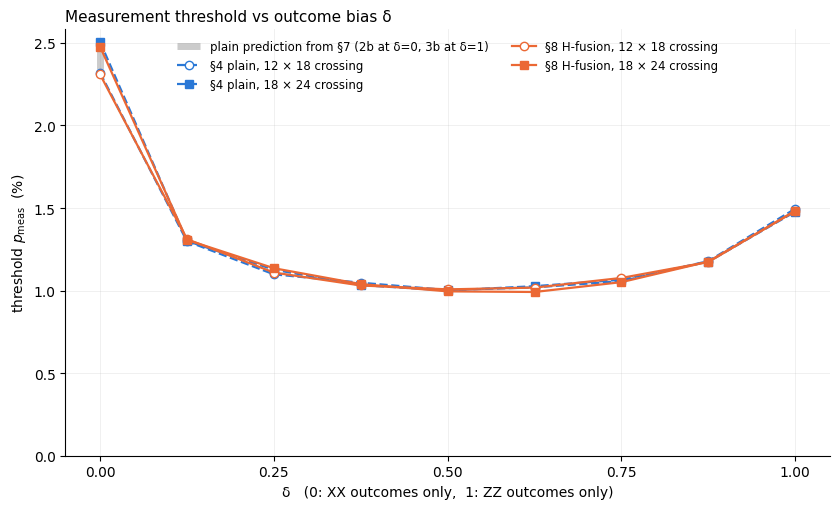

In [23]:
fmt = lambda x: f"{x * 100:.3f}%" if x is not None else "--"
print(f"{'δ':>6} | {'§4 plain 12x18':>14} {'18x24':>8} | {'§8 H-fus 12x18':>14} {'18x24':>8}")
for delta in TH_DELTAS:
    a, b = (th_vs_delta[(v, delta)]['crossings'] for v in VARIANTS)
    print(f"{delta:>6.3f} | {fmt(a[0]):>14} {fmt(a[1]):>8} | {fmt(b[0]):>14} {fmt(b[1]):>8}")

fig, ax = plt.subplots(figsize=(8.5, 5.2))
for k, (d, (lo, hi)) in enumerate(P_TH_PLAIN_ENDS.items()):
    edge = [x * (1 - x) * 100 for x in (lo, hi)]      # XX rate 2p = 2x(1-x)
    ax.plot([d, d], edge, color="0.55", lw=5, alpha=.45, solid_capstyle="butt",
            label="plain prediction from §7 (2b at δ=0, 3b at δ=1)" if k == 0 else None)
CODE_COLOUR = {"§4 plain": "#2a78d6", "§8 H-fusion": "#eb6834"}
PAIR_MARK = {0: ("o", "12 × 18"), 1: ("s", "18 × 24")}
for variant in VARIANTS:
    for k, (mk, pair) in PAIR_MARK.items():
        pts = [(d, th_vs_delta[(variant, d)]['crossings'][k]) for d in TH_DELTAS]
        pts = [(d, x) for d, x in pts if x is not None]
        ax.plot([d for d, _ in pts], [x * 100 for _, x in pts], marker=mk, ms=6, lw=1.6,
                color=CODE_COLOUR[variant], mfc="white" if k == 0 else CODE_COLOUR[variant],
                ls=STYLE[variant]["ls"], label=f"{variant}, {pair} crossing")
ax.set_xlabel("δ   (0: XX outcomes only,  1: ZZ outcomes only)")
ax.set_ylabel("threshold $p_\\mathrm{meas}$  (%)")
ax.set_xticks(np.linspace(0, 1, 5))
ax.set_ylim(bottom=0)
ax.grid(alpha=.22, linewidth=.6)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(fontsize=8.5, frameon=False, loc="upper center", ncol=2)
ax.set_title("Measurement threshold vs outcome bias δ", fontsize=11, loc="left")
fig.tight_layout()
plt.show()

In [24]:
import os

BIAS_TH_DIR = "bias_threshold"
os.makedirs(BIAS_TH_DIR, exist_ok=True)


def save_th_csv(path, results):
    """results: {(circuit, delta): dict(crossings=(12x18, 18x24), ...)}"""
    with open(path, "w") as f:
        f.write("circuit,delta,cross_12x18,cross_18x24\n")
        for (circuit, delta), r in results.items():
            f.write(f"{circuit},{delta}," + ",".join("" if x is None else f"{x:.6g}" for x in r['crossings']) + "\n")


save_th_csv(os.path.join(BIAS_TH_DIR, "hexagonmod2_meas_threshold_vs_delta.csv"), th_vs_delta)
print(f"saved {BIAS_TH_DIR}/hexagonmod2_meas_threshold_vs_delta.csv  (for §14)")

saved bias_threshold/hexagonmod2_meas_threshold_vs_delta.csv  (for §14)


### Result

| `δ` | §4 plain: 12 x 18 / 18 x 24 | §8 H-fusion: 12 x 18 / 18 x 24 |
|---|---|---|
| 0     | 2.32% / 2.51% | 2.31% / 2.48% |
| 0.125 | 1.30% / 1.30% | 1.31% / 1.31% |
| 0.25  | 1.10% / 1.13% | 1.11% / 1.14% |
| 0.375 | 1.05% / 1.03% | 1.03% / 1.04% |
| 0.5   | 1.00% / 1.00% | 1.01% / 1.00% |
| 0.625 | 1.02% / 1.03% | 1.02% / 0.99% |
| 0.75  | 1.06% / 1.07% | 1.08% / 1.05% |
| 0.875 | 1.18% / 1.17% | 1.17% / 1.18% |
| 1     | 1.50% / 1.48% | 1.48% / 1.48% |

**All three predictions hold.**

* **The two circuits have the same threshold at every `δ`**, to within 0.04
  points, which is the crossings' own spread.
* **Plain at the ends matches §7.** `δ = 0` gives 2.32% / 2.51% against the
  2.3-2.5% predicted from case 2b, and it drifts upward with size in the same
  way 2b did. `δ = 1` gives 1.50% / 1.48% against about 1.5% from case 3b.
* **At `δ = 0.5` both circuits give §9's 1.0%.**

Plain is flattest in the middle: within 1.0-1.13% from `δ = 0.25` to `0.75`. It
rises towards both ends, and much more steeply towards `δ = 0`, where it reaches
2.4x its middle value. The jump between `δ = 0.125` (1.30%) and `δ = 0`
(2.3-2.5%) means even a small share of `ZZ` flips costs the circuit most of its
`XX`-only advantage. A plausible reading, not proven here: the `XX`-only decoding
graph splits into `2 Lx/3` disconnected strips (8 / 12 / 16 at Lx = 12 / 18 / 24,
as in §7's case 2b), and even a few `ZZ` edges join them back into the usual two
sectors. (With `ZZ` flips only, or both outcomes, there are just the two sectors.)

The pairwise crossings agree to within 0.03 points everywhere except `δ = 0`
(0.17-0.19 points, still rising with size, as for §7's case 2b).

The never-flipping outcome's weight floor (`Q_FLOOR = 1e-6`) does not matter: re-decoding plain `δ = 0` with floors of `1e-12` and `1e-300`, or with those edges removed entirely, gave identical failure rates and crossings (separate check on this section's noise samples).

---
## 13. Erasure threshold vs `δ`

§12's procedure for §11's biased erasure: each fusion's `XX` outcome is erased
with probability `2 (1 - δ) p` and its `ZZ` outcome with `2 δ p`, decoded with §9's
per-shot erasure reweighting. As in §11, `δ = 0.5` is §9's `p_erase`.

**Only §4 plain is swept.** §8 H-fusion is the same decoding problem (§10), as
§11 and §12 confirm.

**Prediction:** §9's 11.85% at `δ = 0.5`. There is no §7 analogue for erasure,
so the ends are new.

Erasure decoding is per-shot and slow at Lx = 24, so the grid is coarser than
§12's: 10 coarse points from 4% to 30%, 7 fine points from 0.8x to 1.2x the
centre, `δ = 0, 1/4, 1/2, 3/4, 1`, and §9's shot counts (2,000 / 2,000 /
1,000). At those counts the crossings are good to roughly ±0.25 points. The
crossings are saved to `bias_threshold/` for §14.

In [ ]:
TH_DELTAS_E = np.round(np.linspace(0, 1, 5), 4)
TH_COARSE_PS_E = np.round(np.geomspace(0.04, 0.3, 10), 6)
TH_FINE_SPAN_E = (0.8, 1.2, 7)
P_C_ERASE = 0.1185                                      # §9, both circuits
TH_VARIANT = "§4 plain"


def bias_erase_p_sweep(x_max, variant, delta, ps, seed=2028):
    """Logical failure rate vs p_erase at fixed delta -- §11's sweep transposed."""
    S = th_structure(x_max, variant)
    key = (x_max, variant, "erase")
    if key not in _th_raw:
        _th_raw[key] = clean_sample(S, SHOTS_ERASE[x_max], seed)
    raw = _th_raw[key]
    rates = []
    for p in ps:
        q = outcome_rates(x_max, variant, p, delta).astype(np.float32)
        rng = np.random.default_rng((seed, x_max, int(round(p * 1e6)), int(round(delta * 1e4))))
        hit = rng.random(raw.shape, dtype=np.float32) < q
        repl = rng.integers(0, 2, size=raw.shape, dtype=np.uint8)
        rates.append(failure_rate(S, np.where(hit, repl, raw), erased=hit))
    return np.array(rates)


th_vs_delta_e = {}
t_all = time.time()
for delta in TH_DELTAS_E:
    t0 = time.time()
    coarse = [bias_erase_p_sweep(x, TH_VARIANT, delta, TH_COARSE_PS_E) for x in (4, 6)]
    centre = crossing(TH_COARSE_PS_E, coarse[0], coarse[1])
    if centre is None:
        print(f"  δ={delta:.3f}: no 12x18 crossing in the coarse grid", flush=True)
        th_vs_delta_e[(TH_VARIANT, delta)] = dict(ps=TH_COARSE_PS_E, curves=coarse, crossings=(None, None))
        continue
    ps = np.round(centre * np.linspace(*TH_FINE_SPAN_E), 6)
    curves = [bias_erase_p_sweep(x, TH_VARIANT, delta, ps) for x in TH_SIZES]
    xs = tuple(crossing(ps, curves[i], curves[i + 1]) for i in (0, 1))
    th_vs_delta_e[(TH_VARIANT, delta)] = dict(ps=ps, curves=curves, crossings=xs)
    cells_ = "  ".join(f"{(f'{x * 100:.2f}%' if x is not None else '--'):>8}" for x in xs)
    print(f"  δ={delta:.3f}: coarse centre {centre * 100:.2f}%   12x18, 18x24: {cells_}   "
          f"({time.time() - t0:.0f}s)", flush=True)
print(f"\ntotal: {time.time() - t_all:.0f}s")

save_th_csv(os.path.join(BIAS_TH_DIR, "hexagonmod2_erasure_threshold_vs_delta.csv"), th_vs_delta_e)
print(f"saved {BIAS_TH_DIR}/hexagonmod2_erasure_threshold_vs_delta.csv")

  δ=0.000: coarse centre 14.82%   12x18, 18x24:   15.04%    15.54%   (200s)


  δ=0.250: coarse centre 12.10%   12x18, 18x24:   12.05%    11.95%   (526s)


  δ=0.500: coarse centre 11.13%   12x18, 18x24:   12.00%    11.66%   (488s)


  δ=0.750: coarse centre 11.61%   12x18, 18x24:   11.91%    12.01%   (463s)


  δ=1.000: coarse centre 13.61%   12x18, 18x24:   12.44%    12.52%   (528s)



total: 2206s
saved bias_threshold/hexagonmod2_erasure_threshold_vs_delta.csv


     δ | §4 plain 12x18    18x24
 0.000 |         15.04%   15.54%
 0.250 |         12.05%   11.95%
 0.500 |         12.00%   11.66%
 0.750 |         11.91%   12.01%
 1.000 |         12.44%   12.52%


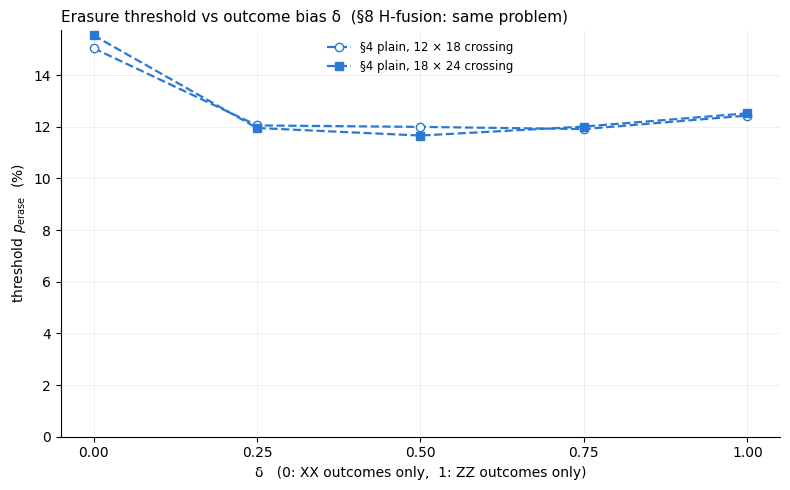

In [27]:
fmt = lambda x: f"{x * 100:.2f}%" if x is not None else "--"
print(f"{'δ':>6} | {'§4 plain 12x18':>14} {'18x24':>8}")
for delta in TH_DELTAS_E:
    xs = th_vs_delta_e[(TH_VARIANT, delta)]['crossings']
    print(f"{delta:>6.3f} | {fmt(xs[0]):>14} {fmt(xs[1]):>8}")

fig, ax = plt.subplots(figsize=(8, 5))
for k, (mk, pair) in enumerate((("o", "12 × 18"), ("s", "18 × 24"))):
    pts = [(d, th_vs_delta_e[(TH_VARIANT, d)]['crossings'][k]) for d in TH_DELTAS_E]
    pts = [(d, x) for d, x in pts if x is not None]
    ax.plot([d for d, _ in pts], [x * 100 for _, x in pts], marker=mk, ms=6, lw=1.6, ls="--",
            color="#2a78d6", mfc="white" if k == 0 else "#2a78d6", label=f"§4 plain, {pair} crossing")
ax.set_xlabel("δ   (0: XX outcomes only,  1: ZZ outcomes only)")
ax.set_ylabel("threshold $p_\\mathrm{erase}$  (%)")
ax.set_xticks(np.linspace(0, 1, 5))
ax.set_ylim(bottom=0)
ax.grid(alpha=.22, linewidth=.6)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(fontsize=8.5, frameon=False, loc="upper center")
ax.set_title("Erasure threshold vs outcome bias δ  (§8 H-fusion: same problem)", fontsize=11, loc="left")
fig.tight_layout()
plt.show()

### Result

| `δ` | §4 plain: 12 x 18 | 18 x 24 |
|---|---|---|
| 0    | 15.0% | 15.5% |
| 0.25 | 12.1% | 12.0% |
| 0.5  | 12.0% | 11.7% |
| 0.75 | 11.9% | 12.0% |
| 1    | 12.4% | 12.5% |

* **`δ = 0.5` matches §9:** 12.0% / 11.7% against 11.85%.
* **For `δ >= 0.25` the erasure threshold is flat**, within 11.7-12.5%, i.e.
  §9's unbiased value to within about half a point.
* **`δ = 0` is the exception, at 15.0-15.5%.** Pure `XX` erasure is tolerated
  at 1.3x the unbiased rate. As for measurement error (§12), this advantage is
  confined to the very end: at `δ = 0.25` the threshold is already back at 12%.
  It is the same end, and plausibly the same mechanism, as §12's jump at `δ = 0`.
* **§8 H-fusion has the same threshold at every `δ`** (§10-§12).

At 1,000-2,000 shots the crossings are good to roughly ±0.25 points.

---
## 14. Comparison with the unmodified hexagon code

The same threshold-vs-`δ` measurement was run on the unmodified hexagon code's
regular-fusion circuit (`Hexagon_fbqc_walkthrough.ipynb` §13-§14), with the same
noise model, decoder, sizes, shots and two-pass method. Both notebooks save
their crossings to `bias_threshold/`, and this section loads them.

Three circuits are compared:

| circuit | what it is |
|---|---|
| hexagon, regular fusion | the unmodified code |
| HexagonMOD2, §4 plain | this notebook's circuit: the hexagon code plus the vertex Hadamard layer |
| H-fusion | this notebook's §8 circuit; the same decoding problem as §4 plain under this noise model (§10) |

At `δ = 0.5` (each outcome at `p`, the unbiased model) all three must agree: the
noise treats both outcomes alike, so each is the hexagon code up to a relabelling
of records. Away from `δ = 0.5`, the Hadamard layer decides which outcome each
check term reads (it is part of the resource state, so it is not a relabelling of
the noise), and so which code tolerates the bias better. The H-fusions on top of
it are a relabelling, so H-fusion and §4 plain must coincide.

Each point is the mean of the 12 x 18 and 18 x 24 crossings, and the bar spans
the two. H-fusion uses this notebook's §12 crossings for `p_meas`; it was not run
for `p_erase`.


meas: threshold (mean of 12x18 and 18x24 crossings)


   hexagon, regular fusion     δ=0.000: 1.48%  δ=0.125: 1.25%  δ=0.250: 1.13%  δ=0.375: 1.07%  δ=0.500: 1.01%  δ=0.625: 1.01%  δ=0.750: 1.01%  δ=0.875: 1.07%
                               not plotted (only one crossing found): δ = 1


   HexagonMOD2, §4 plain       δ=0.000: 2.41%  δ=0.125: 1.30%  δ=0.250: 1.11%  δ=0.375: 1.04%  δ=0.500: 1.00%  δ=0.625: 1.02%  δ=0.750: 1.06%  δ=0.875: 1.18%  δ=1.000: 1.49%
   H-fusion (HexagonMOD2 §12)  δ=0.000: 2.39%  δ=0.125: 1.31%  δ=0.250: 1.12%  δ=0.375: 1.04%  δ=0.500: 1.00%  δ=0.625: 1.00%  δ=0.750: 1.06%  δ=0.875: 1.17%  δ=1.000: 1.48%

erasure: threshold (mean of 12x18 and 18x24 crossings)
   hexagon, regular fusion     δ=0.000: 12.46%  δ=0.250: 12.04%  δ=0.500: 11.98%  δ=0.750: 11.51%  δ=1.000: 12.62%
   HexagonMOD2, §4 plain       δ=0.000: 15.29%  δ=0.250: 12.00%  δ=0.500: 11.83%  δ=0.750: 11.96%  δ=1.000: 12.48%


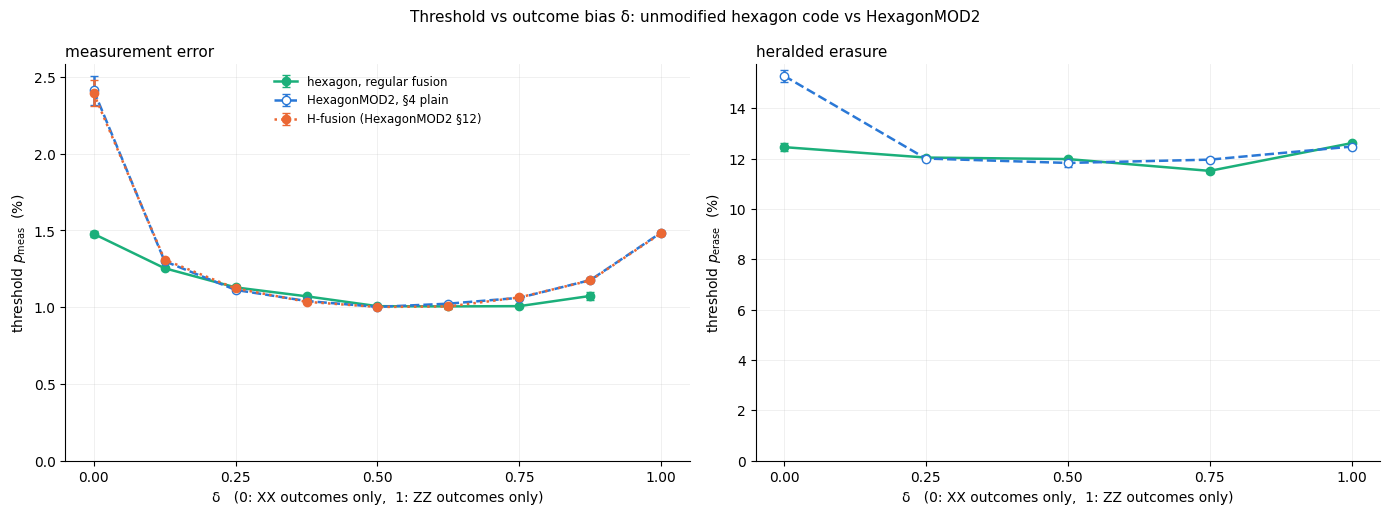

In [28]:
def load_th_csv(path):
    """{(circuit, delta): (12x18, 18x24)} with None for a missing crossing."""
    out = {}
    with open(path) as f:
        next(f)
        for line in f:
            circuit, delta, *xs = line.rstrip("\n").split(",")
            out[(circuit, float(delta))] = tuple(float(x) if x else None for x in xs)
    return out


TH_FILES = {(nb, noise): os.path.join(BIAS_TH_DIR, f"{nb}_{noise}_threshold_vs_delta.csv")
            for nb in ("hexagon", "hexagonmod2") for noise in ("meas", "erasure")}
th_all = {k: load_th_csv(v) for k, v in TH_FILES.items()}

# (label, file key, circuit name in that file, colour, line style)
CMP_SERIES = [("hexagon, regular fusion", "hexagon", "regular fusion", "#1baf7a", "-"),
              ("HexagonMOD2, §4 plain", "hexagonmod2", "§4 plain", "#2a78d6", "--"),
              ("H-fusion (HexagonMOD2 §12)", "hexagonmod2", "§8 H-fusion", "#eb6834", ":")]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, (noise, xlab) in zip(axes, (("meas", "$p_\\mathrm{meas}$"), ("erasure", "$p_\\mathrm{erase}$"))):
    print(f"\n{noise}: threshold (mean of 12x18 and 18x24 crossings)")
    for label, nb, circuit, colour, ls in CMP_SERIES:
        rows = sorted((d, xs) for (c, d), xs in th_all[(nb, noise)].items() if c == circuit)
        # a point needs both crossings; one alone is not a converged threshold
        skipped = [d for d, xs in rows if None in xs]
        rows = [(d, list(xs)) for d, xs in rows if None not in xs]
        if not rows:
            continue
        d = np.array([r[0] for r in rows])
        lo, mid, hi = (np.array([f(r[1]) for r in rows]) * 100 for f in (min, np.mean, max))
        ax.errorbar(d, mid, yerr=[mid - lo, hi - mid], color=colour, ls=ls, lw=1.8, marker="o",
                    ms=6, capsize=3, mfc="white" if ls == "--" else colour, label=label)
        print(f"   {label:<28}" + "  ".join(f"δ={x:.3f}: {m:.2f}%" for x, m in zip(d, mid)))
        if skipped:
            print(f"   {'':<28}not plotted (only one crossing found): δ = {', '.join(f'{x:g}' for x in skipped)}")
    ax.set_xlabel("δ   (0: XX outcomes only,  1: ZZ outcomes only)")
    ax.set_ylabel(f"threshold {xlab}  (%)")
    ax.set_xticks(np.linspace(0, 1, 5))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=.22, linewidth=.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.set_title("measurement error" if noise == "meas" else "heralded erasure", fontsize=11, loc="left")
axes[0].legend(fontsize=8.5, frameon=False, loc="upper center")
fig.suptitle("Threshold vs outcome bias δ: unmodified hexagon code vs HexagonMOD2", fontsize=11)
fig.tight_layout()
plt.show()

### Result

**All three circuits agree at `δ = 0.5`:** about 1.0% for `p_meas` and about
12% for `p_erase`, as the relabelling argument requires. **H-fusion coincides
with §4 plain at every `δ`** (to within 0.03 points for `p_meas`), as it must
under this noise model, so the comparison is really between two codes.

**Measurement error:**

* **The `XX`-only end separates the two codes most.** At `δ = 0` HexagonMOD2
  reaches 2.41% against the hexagon code's 1.48%. That advantage is confined to
  the very end: from `δ = 0.125` to `0.5` the two codes are within 0.05 points of
  each other. HexagonMOD2 is slightly ahead at `0.125` (1.30% vs 1.25%) and
  slightly behind at `0.25` and `0.375` (1.11% vs 1.13%, 1.04% vs 1.07%),
  differences the size of the crossings' own spread.
* **On the `ZZ`-heavy side HexagonMOD2 is ahead too:** 1.06% vs 1.01% at
  `δ = 0.75` and 1.18% vs 1.07% at `0.875`. At `δ = 1` it gives a converged
  1.49%. The hexagon code's 18 x 24 crossing there could not be found at this
  time extent, so that point is not plotted; at twice the time
  (`Hexagon_fbqc_walkthrough.ipynb` §14b) it converges at 1.48% / 1.49%, the same
  as HexagonMOD2.

**Erasure:** for `δ >= 0.25` the two codes agree to within half a point, at
about 12% (HexagonMOD2 0.45 points ahead at `δ = 0.75`, 0.1-0.15 points behind at
`0.5` and `1`). The one clear difference is again at `δ = 0`: 15.3% for
HexagonMOD2 vs 12.5% for the hexagon code.

So the vertex Hadamard layer never makes the code measurably worse against
outcome-biased noise, at least where both codes have a converged threshold. Its
largest effect is a clear gain when the noise is almost entirely on the `XX`
outcomes, with a smaller gain on the `ZZ`-heavy side for measurement error. The
thresholds come from naive crossings at Lx <= 24. For the `δ = 0` and `δ = 1`
points, where the crossings drift with size, a fourth size would be needed before
quoting digits.

### How the error-carrying edges split

The decoder's full graph always splits only into the two sectors (X and Z
checks): it keeps every record's edge, and a slot that never flips just gets a
very large weight. What changes with `δ` is how the edges that *can* carry an
error split up. Counting connected components with checks as nodes and only the
noisy records as edges, at Lx = 12 / 18 / 24:

| circuit | `XX` only (`δ = 0`) | `ZZ` only (`δ = 1`) | both slots (`δ = 0.5`) |
|---|---|---|---|
| hexagon, regular fusion | 2 | **4** | 2 |
| HexagonMOD2, §4 plain | **8 / 12 / 16** | 2 | 2 |
| H-fusion (§8) | as §4 plain | as §4 plain | 2 |

(Where one number is given, it is the same at all three sizes.)

* **HexagonMOD2 plain, `XX` only:** the graph splits into `2 Lx/3` strips,
  `Lx/3` per sector. Each strip is one tile wide, runs the full length of the
  lattice in `y`, and moves one tile in `x` per cycle, so in spacetime it is a
  diagonal sheet. The strips still grow with the lattice (48 / 108 / 192 checks
  each), so each strip is still a decoding problem that grows with the lattice.
* **Hexagon regular:** `XX` only leaves the usual two sectors, but **`ZZ` only
  splits them into 4**, a number that does not grow with size.
* **H-fusion:** with the noise attached to the outcomes, its noisy edges are
  §4 plain's with records relabelled, so the components are the same.

**This lines up with the threshold curves above**, though it is a
correspondence, not a proof:

* HexagonMOD2's large gain at `δ = 0` (2.41% for `p_meas`, 15.3% for
  `p_erase`, against about 1.0% and 12% unbiased) sits exactly where its graph
  breaks into strips. A small share of `ZZ` flips reconnects the strips, and by
  `δ = 0.125` the gain is mostly gone.
* The hexagon code's one unconverged point, `p_meas` at `δ = 1`, sits exactly
  where its graph splits into 4. (`Hexagon_fbqc_walkthrough.ipynb` §14b traces it
  to the time extent: at twice the time it converges, at 1.48% / 1.49%.)
* Wherever the noisy edges form just the two sectors, the threshold stays close
  to the unbiased value.

Testing whether the splitting is what *causes* the shape of these curves would
take more than a component count. (The counts were computed in a separate
check from each notebook's check matrices, not in this notebook.)

---
## Summary

- The vertex three-colouring by `x % 3` meshes exactly with the edge colouring:
  an edge is either **internal**, joining two vertices of its own class, or
  **crossing**, joining the two other classes. A vertex's own-colour edge is
  always its internal one (§1).
- The Hadamard layer is `H on (x, y, t)` iff `(x - t) % 3 == 0`, which puts each
  vertex's Hadamards on **its own colour's steps**. Since a vertex's own-colour
  edge is internal, the layer hits both ends of a fusion or neither, and its only
  effect is to **exchange the two record names on internal-edge fusions** (§3).
- The structure is therefore the unmodified hexagon code's: the same six
  weight-12 hexagon check windows, `2 x (number of hexagons)` per cycle, rank 190
  of 192 on a 4x4 patch at 2 cycles, and the same six logicals.
- **What differs is which record each term pulls**, and that is recorded in the
  two tables this notebook exists for:
  - `CHECK_SPEC` (§5) -- per check type, four `(dt, edge colour, internal slot,
    crossing slot)` rows. Crossing slots run `ZZ, XX, XX, ZZ` in all six; internal
    slots are their exact opposite.
  - `LOGICAL_SPEC` (§6) -- per logical, its family and parameters, with every
    named kind being the **crossing** slot and internal edges taking the opposite.
- Verified against the circuit: DEM builds on all 192 detectors, every check and
  every logical passes `has_flow`, and checks + logicals add exactly 6
  independent dimensions.

- §7 sweeps four noise channels against those tables. Converged: **1.00%**
  (measurement), **1.52%** (`Z` before the Hadamard layer), **1.52%** (`X` after
  it) and **0.49%** (`Y`, a lower bound -- not graphlike, so decoded on an `X`+`Z`
  graph). `Z` after the layer (~2.4%) is still drifting with size, and `X` before
  it shows **no threshold** in the scanned window: `Lx = 24` does worse than
  `Lx = 18` above `p` = 1.1%. `Z` and `X` are each swept at both splice points
  because the Hadamard layer converts them (`Z <-> X`) on the qubits it touches;
  `Y` is swept once because `H Y H = -Y` makes the two placements identical.

- §8 adds H-fusions on the `XX`-step crossing edges and the `ZZ`-step internal
  edges. Combined with the Hadamard layer, this exchanges the record names on
  every `XX`-step fusion and on no `ZZ`-step fusion. The result: X checks read
  only `XX` records, Z checks only `ZZ` records (`CHECK_SPEC_H`), and each
  logical term reads its `LOGICAL_SPEC` kind on `ZZ` steps and the opposite
  kind on `XX` steps. All of this is verified against the circuit. Vertical Z
  touches no H-fused fusion and is unchanged.
- §9: the thresholds are unchanged by the H-fusions. `p_meas` is about 1.00%
  and `p_erase` about 11.8-11.9%, for both circuits.
- §10-§13 bias the fusion-outcome noise between the two measured operators
  with a parameter `δ` (`X_aX_b` at `2 (1 - δ) p`, `Z_aZ_b` at `2 δ p`, measured on
  the qubits as they arrive at the fusion), so `δ = 0.5` is §9's model. The
  H-fusions only relabel which record holds which outcome, so the two circuits
  are the same decoding problem and agree at every `δ` (§10-§12). The `p_meas`
  threshold never drops below §9's value: it rises to 1.5% at `δ = 1` and
  2.3-2.5% at `δ = 0`, matching §7's cases 3b and 2b. The `p_erase` threshold
  stays near 12%, except 15-15.5% at `δ = 0` (§13).
- §14 compares against the unmodified hexagon code
  (`Hexagon_fbqc_walkthrough.ipynb` §13-§14). All circuits agree at `δ = 0.5`.
  Wherever both codes have a converged threshold, this one is never measurably
  worse, and it is clearly better at `δ = 0` (2.41% vs 1.48% for `p_meas`,
  15.3% vs 12.5% for `p_erase`).

Because the network is the hexagon code up to a relabelling, the measurement
threshold is a useful consistency target: a sweep on this circuit that disagrees
with the unmodified code points to a labelling bug rather than to new physics.